In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import scipy.stats as st
# from statsmodels.stats.multitest import multipletests


import os
import datetime






sns.set_context('paper')
import gseapy


# gseapy.get_library_name()



from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings("ignore")
import sys
sys.path.append('/lustre1/home/martinmikl/sshanas/bin')
from div import *

sys.path.append('.')
from fig4funcs import *
sns.set_context('paper')
plt.rcParams.update({
    'font.size': 10 * 0.6,
    'axes.titlesize': 10 * 0.6,
    'axes.labelsize': 10 * 0.6,
    'xtick.labelsize': 10 * 0.6,
    'ytick.labelsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'figure.titlesize': 12 * 0.6,
    'legend.title_fontsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans']
})

def nnow():
    print(datetime.datetime.now().strftime('%Y-%m-%d  %H:%M:%S'))
nnow()

# c_mapp = sns.diverging_palette(20, 220, as_cmap=True)
c_mapp = sns.diverging_palette(10, 620, as_cmap=True)

# s_colors =  ["#2ca02c", "#ff6f61", "#1f77b4"]
s_colors =  ["#ff6f61", "#1f77b4", "#2ca02c"] 

%load_ext autoreload
%autoreload 2

2026-10-13  12:17:17


In [ ]:
metadata = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_upstream_git/metadata.csv.gz', index_col=0)
gene_info = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_upstream_git/gene_annotation.csv.gz', index_col=0)


spearman_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_pre_downstream_git/spearman/'
multiple_linear_regression_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_pre_downstream_git/fig4_mlr/per_gene/'

lme_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_pre_downstream_git/fig4_lme/'
lmm_technical_cov_excluded_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_pre_downstream_git/fig4_lme/lme_across_SMTS_exRINISCH/lme_across_SMTS_exRINISCH.lme.tpm.allcoefs.wide.csv.gz'

mele2015_S12_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/input_files_git/mele2015.AgeDiffExpGenes.S12.csv'

In [ ]:
def style_axis(ax):
    ax.tick_params(length=2.5)
    ax.set_yticklabels(ax.get_yticklabels(), x=0)
    ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
    ax.set_xlabel(ax.get_xlabel(), labelpad=0)
    ax.set_ylabel(ax.get_ylabel(), labelpad=0)
    
def annotpval(pv):
    if float(f'{pv:.2e}') == 0.00e+00:
        return 'p<10^-323'
    else:
        return f'p={pv:.2e}'.replace("e", "x10^")
    
brain_regions_abb = {
    'Brain - Cortex': 'CTX',
    'Brain - Cerebellum': 'CBL',
    'Brain - Hippocampus': 'HIP',
    'Brain - Anterior cingulate cortex (BA24)': 'ACC',
    'Brain - Caudate (basal ganglia)': 'CAU',
    'Brain - Nucleus accumbens (basal ganglia)': 'NAC',
    'Brain - Putamen (basal ganglia)': 'PUT',
    'Brain - Frontal Cortex (BA9)': 'FCX',
    'Brain - Cerebellar Hemisphere': 'CBH',
    'Brain - Hypothalamus': 'HYP',
    'Brain - Substantia nigra': 'SNI',
    'Brain - Spinal cord (cervical c-1)': 'SPC',
    'Brain - Amygdala': 'AMY',
}
pth = os.getcwd() + '/'
abb_SMTS = {t: t.replace(' Tissue', '').replace('Gland', 'G.').replace('Vessel', 'V.') for t in metadata.SMTS.unique()}
tables_main_path = pth + 'tables_main/'

if not os.path.isdir(pth +'figs_lme/'):
    os.mkdir(pth + 'figs_lme/')
if not os.path.isdir(pth + 'tables_lme/'):
    os.mkdir(pth + 'tables_lme/')

source_data_path = pth + 'source_data/'
supplementary_data_path = pth + 'supplementary_data/'

if not os.path.isdir(source_data_path):
    os.mkdir(source_data_path)
if not os.path.isdir(supplementary_data_path):
    os.mkdir(supplementary_data_path)


# overview

In [ ]:
tdiv_smts_spearman_corrs = pd.DataFrame(index=metadata.SMTS.unique())
tdiv_smts_spearman_corrs = tdiv_smts_spearman_corrs.assign(rho = metadata.groupby('SMTS').apply(lambda group: st.spearmanr(group['div'], group['AGE_int'])[0]), 
                                                           p = metadata.groupby('SMTS').apply(lambda group: st.spearmanr(group['div'], group['AGE_int'])[1]), 
                                                           feature = 'T-DIV')
mdiv_smts_spearman_corrs = pd.DataFrame(index=metadata.SMTS.unique())
mdiv_smts_spearman_corrs = mdiv_smts_spearman_corrs.assign(rho = metadata.groupby('SMTS').apply(lambda group: st.spearmanr(group['meanisofdiv'], group['AGE_int'])[0]), 
                                                           p = metadata.groupby('SMTS').apply(lambda group: st.spearmanr(group['meanisofdiv'], group['AGE_int'])[1]), 
                                                           feature = 'µ I-DIV')
tdiv_brain_spearman_corrs = pd.DataFrame(index=metadata.loc[metadata.SMTS=='Brain'].SMTSD.unique())
tdiv_brain_spearman_corrs = tdiv_brain_spearman_corrs.assign(rho = metadata.loc[metadata.SMTS=='Brain'].groupby('SMTSD').apply(lambda group: st.spearmanr(group['div'], group['AGE_int'])[0]), 
                                                             p = metadata.loc[metadata.SMTS=='Brain'].groupby('SMTSD').apply(lambda group: st.spearmanr(group['div'], group['AGE_int'])[1]),
                                                             feature = 'T-DIV')
mdiv_brain_spearman_corrs = pd.DataFrame(index=metadata.loc[metadata.SMTS=='Brain'].SMTSD.unique())
mdiv_brain_spearman_corrs = mdiv_brain_spearman_corrs.assign(rho = metadata.loc[metadata.SMTS=='Brain'].groupby('SMTSD').apply(lambda group: st.spearmanr(group['meanisofdiv'], group['AGE_int'])[0]), 
                                                             p = metadata.loc[metadata.SMTS=='Brain'].groupby('SMTSD').apply(lambda group: st.spearmanr(group['meanisofdiv'], group['AGE_int'])[1]),
                                                             feature = 'µ I-DIV')

smts_spearman_corrs = pd.concat([tdiv_smts_spearman_corrs.reset_index(), mdiv_smts_spearman_corrs.reset_index()])
brain_spearman_corrs = pd.concat([tdiv_brain_spearman_corrs.reset_index(), mdiv_brain_spearman_corrs.reset_index()])

del tdiv_smts_spearman_corrs, mdiv_smts_spearman_corrs
del tdiv_brain_spearman_corrs, mdiv_brain_spearman_corrs

smts_spearman_corrs.rename(columns={'index': 'SMTS'}, inplace=True)
brain_spearman_corrs.rename(columns={'index': 'SMTSD'}, inplace=True)

smts_spearman_corrs = smts_spearman_corrs.assign(significant = smts_spearman_corrs.p < 0.05)
brain_spearman_corrs = brain_spearman_corrs.assign(significant = brain_spearman_corrs.p < 0.05)

smts_order = smts_spearman_corrs.loc[smts_spearman_corrs['feature'] == 'T-DIV'].sort_values('rho', ascending=False).SMTS.values
brain_order = brain_spearman_corrs.loc[brain_spearman_corrs['feature'] == 'T-DIV'].sort_values('rho', ascending=False).SMTSD.values

signifiance_handel = [Line2D([], [], marker='o', linestyle='None', markerfacecolor='dimgrey',markeredgecolor='none', markersize=3, label='p>0.05'),
                      Line2D([], [], marker='D', linestyle='None', markerfacecolor='dimgrey',markeredgecolor='none', markersize=3, label='p<0.05')]

if not os.path.isdir('figs_lme/overview_age/'):
    os.mkdir('figs_lme/overview_age/')

In [18]:
smts_spearman_corrs.loc[smts_spearman_corrs.SMTS=='Muscle']

,SMTS,rho,p,feature,significant
2,Muscle,0.149212,0.023015,T-DIV,True
2,Muscle,0.207937,0.001448,µ I-DIV,True


In [32]:
f"{smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS=='Muscle') & (smts_spearman_corrs.feature=='µ I-DIV'), 'p'].values[0]:.3f}"

'0.001'

In [46]:
t = "Muscle"; m = 'µ I-DIV'
print(f"{m}\nrho={smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'rho'].values[0]:.2f}, p={smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'p'].values[0]:.3f}")
m = 'T-DIV'
print(f"{m}\nrho={smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'rho'].values[0]:.2f}, p={smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'p'].values[0]:.2f}")

µ I-DIV
rho=0.21, p=0.001
T-DIV
rho=0.15, p=0.02


In [50]:
t = "Brain"; m = 'µ I-DIV'
print(f"{m}\nrho={smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'rho'].values[0]:.2f}, {annotpval(smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'p'].values[0])}")
m = 'T-DIV'
print(f"{m}\nrho={smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'rho'].values[0]:.2f}, {annotpval(smts_spearman_corrs.loc[(smts_spearman_corrs.SMTS==t) & (smts_spearman_corrs.feature==m), 'p'].values[0])}")

µ I-DIV
rho=-0.11, p=1.55x10^-05
T-DIV
rho=0.02, p=5.03x10^-01


In [ ]:
whatp = ''
hheight_smts=len(smts_order)/9

cpalette = {'T-DIV': 'Coral', 'µ I-DIV': 'Teal'}
fig, ax = plt.subplots(figsize=(0.75,hheight_smts))
for f in smts_spearman_corrs.feature.unique():
    tempdf = smts_spearman_corrs.loc[(smts_spearman_corrs.feature ==f)].set_index('SMTS').loc[smts_order]
    sns.scatterplot(data = tempdf.reset_index(), 
                    y = 'SMTS', x = 'rho', c=cpalette[f], s = 20, alpha = 0.7, edgecolor='None', 
                    style='significant', markers=['o', 'D'], legend=False,
                    zorder=2)
plt.axvline(0, 0,1, color='silver', linestyle='-', linewidth=0.5,zorder=0)

ax.set_xlim(ax.get_xlim()[0] * 1.4,ax.get_xlim()[1]*1.2)
# ax.grid(axis='y', zorder = 1, c='silver', alpha = 0.5, linestyle='--')
legend_handles = [Line2D([], [], marker='o', linestyle='None', markerfacecolor=cpalette[m],markeredgecolor='none', markersize=3, label=m + '~AGE') for m in cpalette.keys()] + signifiance_handel
ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.45,1))

age_by_smts = metadata.SMTS.value_counts().to_frame().rename(columns={'count': 'n'})
age_by_smts = age_by_smts.loc[smts_order]
# ax.text(x = 0.55, y = -0.9, s='n=', color='black', fontsize=8)
for i,t in enumerate(age_by_smts.index):
    ax.text(x = 0.6, y = i + 0.5, s=age_by_smts.loc[t, 'n'], color='dimgrey')



ax.set(xlabel ="Spearmans's ρ", ylabel='SMTS')
ax.tick_params(length=2.5)
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()], x=0.01)
ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0.01)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel('SMTS tissues', labelpad=0)
sns.despine()
fig.savefig('figs_lme/overview_age/SMTS_spearman_AGE.stripplot.png', format='png', dpi=300, bbox_inches='tight')

In [ ]:
whatp = ''
hheight_smts=len(brain_order)/9

cpalette = {'T-DIV': 'Coral', 'µ I-DIV': 'Teal'}
fig, ax = plt.subplots(figsize=(0.75,hheight_smts))
for f in brain_spearman_corrs.feature.unique():
    tempdf = brain_spearman_corrs.loc[(brain_spearman_corrs.feature ==f)].set_index('SMTSD').loc[brain_order]
    sns.scatterplot(data = tempdf.reset_index(), 
                    y = 'SMTSD', x = 'rho', c=cpalette[f], s = 20, alpha = 0.7, edgecolor='None', 
                    style='significant', markers=['o', 'D'], legend=False,
                    zorder=2)
plt.axvline(0, 0,1, color='silver', linestyle='-', linewidth=0.5,zorder=0)

ax.set_xlim(ax.get_xlim()[0] * 1.4,ax.get_xlim()[1]*1.2)
# ax.grid(axis='y', zorder = 1, c='silver', alpha = 0.5, linestyle='--')
legend_handles = [Line2D([], [], marker='o', linestyle='None', markerfacecolor=cpalette[m],markeredgecolor='none', markersize=3, label=m + '~AGE') for m in cpalette.keys()] + signifiance_handel
ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.45,1))

age_by_brain = metadata.loc[metadata.SMTS == 'Brain'].SMTSD.value_counts().to_frame().rename(columns={'count': 'n'})
age_by_brain = age_by_brain.loc[brain_order]
# ax.text(x = 0.55, y = -0.9, s='n=', color='black', fontsize=8)
for i,t in enumerate(age_by_brain.index):
    ax.text(x = 0.3, y = i + 0.5, s=age_by_brain.loc[t, 'n'], color='dimgrey')



ax.set(xlabel ="Spearmans's ρ", ylabel='SMTS')
ax.tick_params(length=2.5)
ax.set_yticklabels([brain_regions_abb[y.get_text()] for y in ax.get_yticklabels()], x=0.01)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15,ha='right', y=0.01)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel('Brain SMTSD tissues', labelpad=0)
sns.despine()
fig.savefig('figs_lme/overview_age/SMTSDbrain_spearman_AGE.stripplot.png', format='png', dpi=300, bbox_inches='tight')

I think we should say we did it in two ways (which is really what we did): One for general trends across (sub)tissues (LMM),   
and one with multiple linear regression per subtissue. The latter showed that especially in the brain subtissues there are a lot of genes with div changing with age --> we focused on the brain.  
We can take the top 30 list of genes from the LMM, or we can take the top 30 list of genes from LMM that are also significant in a subtissue.

# Mulitple linar regression per SMTSD tissue (limma)
`y ~ age_int + SEX + SMRIN + SMTSISCH (+ SMTSD)`

In [ ]:
##### LIMMA (multiple linear regression) results across SMTSD tissues for AGE and SEX coefficients #### 
tissues_dirs = [f.split('.')[0] for f in os.listdir(multiple_linear_regression_path + 'per_gene/SMTSD/') if f.endswith('.limma.tpm.coefficients.csv.gz')]

smtsd_limma_tpm = pd.concat([pd.read_csv(multiple_linear_regression_path + f'SMTSD/{t}.limma.tpm.coefficients.csv.gz').assign(SMTSD=t) for t in tissues_dirs])
smtsd_limma_div = pd.concat([pd.read_csv(multiple_linear_regression_path + f'SMTSD/{t}.limma.div.coefficients.csv.gz').assign(SMTSD=t) for t in tissues_dirs])

tissue_map = {
    'Prostate': 'Prostate',
    'Brain_-_Amygdala': 'Brain - Amygdala',
    'Uterus': 'Uterus',
    'Breast_-_Mammary_Tissue': 'Breast - Mammary Tissue',
    'Esophagus_-_Muscularis': 'Esophagus - Muscularis',
    'Esophagus_-_Gastroesophageal_Junction': 'Esophagus - Gastroesophageal Junction',
    'Colon_-_Sigmoid': 'Colon - Sigmoid',
    'Adipose_-_Visceral_Omentum_': 'Adipose - Visceral (Omentum)',
    'Brain_-_Substantia_nigra': 'Brain - Substantia nigra',
    'Thyroid': 'Thyroid',
    'Skin_-_Sun_Exposed_Lower_leg_': 'Skin - Sun Exposed (Lower leg)',
    'Stomach': 'Stomach',
    'Cells_-_Cultured_fibroblasts': 'Cells - Cultured fibroblasts',
    'Whole_Blood': 'Whole Blood',
    'Brain_-_Nucleus_accumbens_basal_ganglia_': 'Brain - Nucleus accumbens (basal ganglia)',
    'Brain_-_Hypothalamus': 'Brain - Hypothalamus',
    'Esophagus_-_Mucosa': 'Esophagus - Mucosa',
    'Heart_-_Atrial_Appendage': 'Heart - Atrial Appendage',
    'Lung': 'Lung',
    'Vagina': 'Vagina',
    'Artery_-_Aorta': 'Artery - Aorta',
    'Brain_-_Caudate_basal_ganglia_': 'Brain - Caudate (basal ganglia)',
    'Brain_-_Hippocampus': 'Brain - Hippocampus',
    'Testis': 'Testis',
    'Brain_-_Spinal_cord_cervical_c-1_': 'Brain - Spinal cord (cervical c-1)',
    'Liver': 'Liver',
    'Kidney_-_Cortex': 'Kidney - Cortex',
    'Brain_-_Cerebellum': 'Brain - Cerebellum',
    'Brain_-_Putamen_basal_ganglia_': 'Brain - Putamen (basal ganglia)',
    'Artery_-_Tibial': 'Artery - Tibial',
    'Minor_Salivary_Gland': 'Minor Salivary Gland',
    'Skin_-_Not_Sun_Exposed_Suprapubic_': 'Skin - Not Sun Exposed (Suprapubic)',
    'Brain_-_Frontal_Cortex_BA9_': 'Brain - Frontal Cortex (BA9)',
    'Brain_-_Cortex': 'Brain - Cortex',
    'Pancreas': 'Pancreas',
    'Artery_-_Coronary': 'Artery - Coronary',
    'Adrenal_Gland': 'Adrenal Gland',
    'Adipose_-_Subcutaneous': 'Adipose - Subcutaneous',
    'Brain_-_Anterior_cingulate_cortex_BA24_': 'Brain - Anterior cingulate cortex (BA24)',
    'Cells_-_EBV-transformed_lymphocytes': 'Cells - EBV-transformed lymphocytes',
    'Pituitary': 'Pituitary',
    'Brain_-_Cerebellar_Hemisphere': 'Brain - Cerebellar Hemisphere',
    'Colon_-_Transverse': 'Colon - Transverse',
    'Nerve_-_Tibial': 'Nerve - Tibial',
    'Muscle_-_Skeletal': 'Muscle - Skeletal',
    'Ovary': 'Ovary',
    'Heart_-_Left_Ventricle': 'Heart - Left Ventricle',
}

smtsd_limma_tpm['SMTSD'] = smtsd_limma_tpm['SMTSD'].map(tissue_map)
smtsd_limma_div['SMTSD'] = smtsd_limma_div['SMTSD'].map(tissue_map)



In [155]:
limma_coeff_tpm_df = smtsd_limma_tpm.loc[smtsd_limma_tpm.SMTSD.str.contains('Brain'),['age_int_coef', 'age_int_FDR', 'gene', 'SMTSD']].pivot(index='gene', columns='SMTSD', values='age_int_coef')
limma_fdr_tpm_df = smtsd_limma_tpm.loc[smtsd_limma_tpm.SMTSD.str.contains('Brain'),['age_int_coef', 'age_int_FDR', 'gene', 'SMTSD']].pivot(index='gene', columns='SMTSD', values='age_int_FDR')
limma_astr_tpm_df = limma_fdr_tpm_df.applymap(pval_to_asterisks)

limma_coeff_div_df = smtsd_limma_div.loc[smtsd_limma_div.SMTSD.str.contains('Brain'),['age_int_coef', 'age_int_FDR', 'gene', 'SMTSD']].pivot(index='gene', columns='SMTSD', values='age_int_coef')
limma_fdr_div_df = smtsd_limma_div.loc[smtsd_limma_div.SMTSD.str.contains('Brain'),['age_int_coef', 'age_int_FDR', 'gene', 'SMTSD']].pivot(index='gene', columns='SMTSD', values='age_int_FDR')
limma_astr_div_df = limma_fdr_div_df.applymap(pval_to_asterisks)


limma_coeff_tpm_df = limma_coeff_tpm_df.join(gene_info.gene_name).set_index('gene_name')
limma_astr_tpm_df = limma_astr_tpm_df.join(gene_info.gene_name).set_index('gene_name')
limma_fdr_tpm_df = limma_fdr_tpm_df.join(gene_info.gene_name).set_index('gene_name')
limma_coeff_div_df = limma_coeff_div_df.join(gene_info.gene_name).set_index('gene_name')
limma_astr_div_df = limma_astr_div_df.join(gene_info.gene_name).set_index('gene_name')
limma_fdr_div_df = limma_fdr_div_df.join(gene_info.gene_name).set_index('gene_name')


In [156]:
hm_count = pd.DataFrame(index=smtsd_limma_tpm.SMTSD.unique())
hm_count = hm_count.join(smtsd_limma_tpm.loc[smtsd_limma_tpm.age_int_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'TPM AGE'}).join(smtsd_limma_div.loc[smtsd_limma_div.age_int_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'I-DIV AGE'})))
hm_count = hm_count.join(smtsd_limma_tpm.loc[smtsd_limma_tpm.SMRIN_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'TPM RIN'}).join(smtsd_limma_div.loc[smtsd_limma_div.SMRIN_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'I-DIV RIN'})))
hm_count = hm_count.join(smtsd_limma_tpm.loc[smtsd_limma_tpm.SMTSISCH_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'TPM SMTSISCH'}).join(smtsd_limma_div.loc[smtsd_limma_div.SMTSISCH_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'I-DIV SMTSISCH'})))
hm_count = hm_count.join(smtsd_limma_tpm.loc[smtsd_limma_tpm.SEXFemale_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'TPM SEX'}).join(smtsd_limma_div.loc[smtsd_limma_div.SEXFemale_FDR < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'I-DIV SEX'})))
hm_count = hm_count.join(smtsd_limma_tpm.groupby('SMTSD')['n_samples'].first().rename('n'))
hm_count

,TPM AGE,I-DIV AGE,TPM RIN,I-DIV RIN,TPM SMTSISCH,I-DIV SMTSISCH,TPM SEX,I-DIV SEX,n
Prostate,266.0,1.0,1.0,3.0,NaN,NaN,NaN,NaN,43
Brain - Amygdala,839.0,1.0,776.0,465.0,NaN,NaN,NaN,NaN,73
Uterus,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18
Breast - Mammary Tissue,NaN,NaN,256.0,2.0,NaN,NaN,7447.0,1154.0,93
Esophagus - Muscularis,NaN,NaN,3340.0,2513.0,NaN,NaN,NaN,NaN,73
Esophagus - Gastroesophageal Junction,NaN,NaN,2306.0,1754.0,NaN,NaN,NaN,NaN,60
Colon - Sigmoid,2.0,NaN,13.0,1.0,NaN,NaN,NaN,NaN,54
Adipose - Visceral (Omentum),NaN,NaN,1346.0,268.0,103.0,15.0,9.0,NaN,129
Brain - Substantia nigra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65
Thyroid,36.0,NaN,1239.0,823.0,316.0,397.0,1412.0,9.0,172


[Text(0, 0.5, 'Brain - Frontal Cortex (BA9)'),
 Text(0, 1.5, 'Brain - Hippocampus'),
 Text(0, 2.5, 'Brain - Hypothalamus'),
 Text(0, 3.5, 'Artery - Tibial'),
 Text(0, 4.5, 'Artery - Aorta'),
 Text(0, 5.5, 'Muscle - Skeletal'),
 Text(0, 6.5, 'Cells - Cultured fibroblasts'),
 Text(0, 7.5, 'Brain - Cerebellum'),
 Text(0, 8.5, 'Brain - Nucleus accumbens (basal ganglia)'),
 Text(0, 9.5, 'Brain - Anterior cingulate cortex (BA24)'),
 Text(0, 10.5, 'Whole Blood'),
 Text(0, 11.5, 'Thyroid'),
 Text(0, 12.5, 'Breast - Mammary Tissue'),
 Text(0, 13.5, 'Skin - Sun Exposed (Lower leg)'),
 Text(0, 14.5, 'Brain - Caudate (basal ganglia)'),
 Text(0, 15.5, 'Lung'),
 Text(0, 16.5, 'Esophagus - Mucosa'),
 Text(0, 17.5, 'Heart - Atrial Appendage'),
 Text(0, 18.5, 'Adipose - Visceral (Omentum)'),
 Text(0, 19.5, 'Brain - Spinal cord (cervical c-1)'),
 Text(0, 20.5, 'Liver'),
 Text(0, 21.5, 'Testis'),
 Text(0, 22.5, 'Skin - Not Sun Exposed (Suprapubic)'),
 Text(0, 23.5, 'Brain - Putamen (basal ganglia)'),
 Te

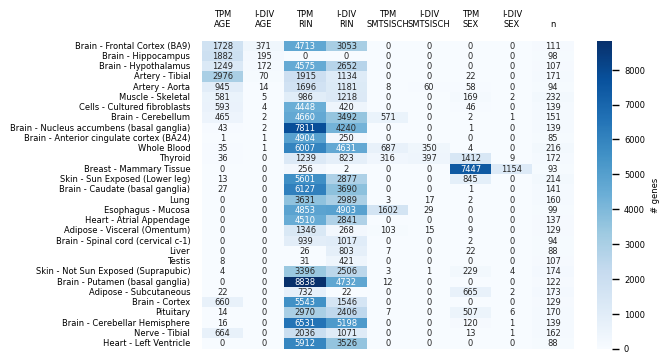

In [157]:
fig, ax = plt.subplots(figsize=(6,4))
sns.heatmap(hm_count.loc[hm_count['n'] > 75].fillna(0).astype(int).sort_values('I-DIV AGE', ascending=False), annot=True,fmt='d', cmap='Blues', cbar_kws={'label': '# genes'})
ax.xaxis.tick_top()
ax.tick_params(left=False, bottom=False, top=False) 
ax.set_xticklabels([x.get_text().replace(' ', '\n') for x in ax.get_xticklabels()], rotation=0, ha='center')
ax.set_yticklabels(ax.get_yticklabels(),x=0)

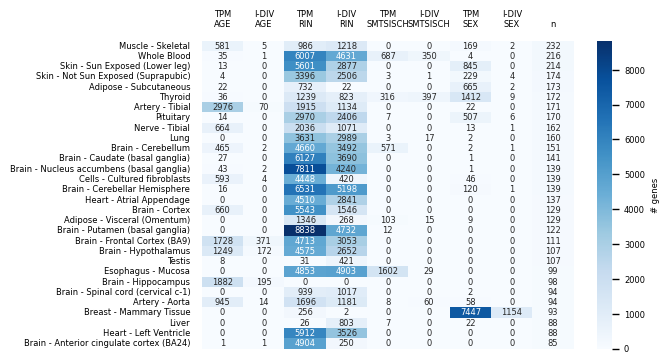

In [ ]:

if os.path.isdir('figs_lme/limma') == False:
    os.mkdir('figs_lme/limma')


fig, ax = plt.subplots(figsize=(6,4))
sns.heatmap(hm_count.loc[hm_count['n'] > 75].fillna(0).astype(int).sort_values('n', ascending=False), annot=True,fmt='d', cmap='Blues', cbar_kws={'label': '# genes'})
ax.xaxis.tick_top()
ax.tick_params(left=False, bottom=False, top=False) 
ax.set_xticklabels([x.get_text().replace(' ', '\n') for x in ax.get_xticklabels()], rotation=0, ha='center')
ax.set_yticklabels(ax.get_yticklabels(),x=0)
# fig.savefig('figs_lme/limma/smtsd.hm.png', format='png', dpi=300, bbox_inches='tight')

In [165]:
hm_count_manysmpls = hm_count.loc[hm_count['n'] > 75]
hm_count_manysmpls.sort_values('I-DIV AGE', ascending=False)

,TPM AGE,I-DIV AGE,TPM RIN,I-DIV RIN,TPM SMTSISCH,I-DIV SMTSISCH,TPM SEX,I-DIV SEX,n
Brain - Frontal Cortex (BA9),1728.0,371.0,4713.0,3053.0,NaN,NaN,NaN,NaN,111
Brain - Hippocampus,1882.0,195.0,NaN,NaN,NaN,NaN,NaN,NaN,98
Brain - Hypothalamus,1249.0,172.0,4575.0,2652.0,NaN,NaN,NaN,NaN,107
Artery - Tibial,2976.0,70.0,1915.0,1134.0,NaN,NaN,22.0,NaN,171
Artery - Aorta,945.0,14.0,1696.0,1181.0,8.0,60.0,58.0,NaN,94
Muscle - Skeletal,581.0,5.0,986.0,1218.0,NaN,NaN,169.0,2.0,232
Cells - Cultured fibroblasts,593.0,4.0,4448.0,420.0,NaN,NaN,46.0,NaN,139
Brain - Cerebellum,465.0,2.0,4660.0,3492.0,571.0,NaN,2.0,1.0,151
Brain - Nucleus accumbens (basal ganglia),43.0,2.0,7811.0,4240.0,NaN,NaN,1.0,NaN,139
Whole Blood,35.0,1.0,6007.0,4631.0,687.0,350.0,4.0,NaN,216


# Spearman per SMTSD tissue   
`y ~ AGE(3 groups)`

In [158]:
spearman_div_coef_df, spearman_div_fdr_df = make_spearmanres_dfs(m='div')
spearman_tpm_coef_df, spearman_tpm_fdr_df = make_spearmanres_dfs(m='tpm')

spearman_div_astr_df = spearman_div_fdr_df.applymap(pval_to_asterisks)
spearman_tpm_astr_df = spearman_tpm_fdr_df.applymap(pval_to_asterisks)

In [ ]:
tissues_dirs = [f.split('.')[0] for f in os.listdir(spearman_path + 'SMTSD/') if f.endswith('.spearmanr.tpm.csv.gz')]

smtsd_spearmanr_tpm = pd.concat([pd.read_csv(spearman_path + f'SMTSD/{t}.spearmanr.tpm.csv.gz').assign(SMTSD=t) for t in tissues_dirs])
smtsd_spearmanr_div = pd.concat([pd.read_csv(spearman_path + f'SMTSD/{t}.spearmanr.div.csv.gz').assign(SMTSD=t) for t in tissues_dirs])
smtsd_spearmanr_tpm['fdr'] = (smtsd_spearmanr_tpm.groupby('SMTSD')['p_val'].transform(lambda p: correct_pvalues_with_nan(p, method='fdr_bh', alpha=0.05)[1]))
smtsd_spearmanr_div['fdr'] = (smtsd_spearmanr_div.groupby('SMTSD')['p_val'].transform(lambda p: correct_pvalues_with_nan(p, method='fdr_bh', alpha=0.05)[1]))

def count_sig(df, label):
    sig = df[df.fdr < 0.05]
    pos = sig[sig.coef > 0].groupby('SMTSD').size().rename(f'{label}_nsignificant+')
    neg = sig[sig.coef < 0].groupby('SMTSD').size().rename(f'{label}_nsignificant-')
    return pd.concat([pos, neg], axis=1)

hm_count_sp = (
    count_sig(smtsd_spearmanr_tpm, 'tpm')
    .join(count_sig(smtsd_spearmanr_div, 'div'), how='outer')
    .reindex(smtsd_spearmanr_tpm.SMTSD.unique())
    .fillna(0).astype(int)
    .join(metadata.SMTSD.value_counts().rename('n'))
)
hm_count_sp

,tpm_nsignificant+,tpm_nsignificant-,div_nsignificant+,div_nsignificant-,n
SMTSD,,,,,
Artery - Aorta,420,475,1,0,94
Uterus,0,0,1,0,18
Esophagus - Mucosa,0,0,0,0,99
Brain - Cortex,1036,1852,13,56,129
Muscle - Skeletal,443,550,3,0,232
Brain - Anterior cingulate cortex (BA24),1370,1829,109,532,85
Skin - Sun Exposed (Lower leg),11,4,0,0,214
Vagina,0,0,0,0,17
Adrenal Gland,1,0,0,0,36


In [ ]:
if os.path.isdir('figs_lme/spearmanr/') == False:
    os.mkdir('figs_lme/spearmanr/')

[Text(0.05, 0.5, 'Brain - Hypothalamus'),
 Text(0.05, 1.5, 'Brain - Anterior cingulate cortex (BA24)'),
 Text(0.05, 2.5, 'Brain - Hippocampus'),
 Text(0.05, 3.5, 'Artery - Tibial'),
 Text(0.05, 4.5, 'Brain - Frontal Cortex (BA9)'),
 Text(0.05, 5.5, 'Brain - Nucleus accumbens (basal ganglia)'),
 Text(0.05, 6.5, 'Brain - Cortex'),
 Text(0.05, 7.5, 'Thyroid'),
 Text(0.05, 8.5, 'Breast - Mammary Tissue'),
 Text(0.05, 9.5, 'Brain - Cerebellar Hemisphere'),
 Text(0.05, 10.5, 'Brain - Cerebellum'),
 Text(0.05, 11.5, 'Muscle - Skeletal'),
 Text(0.05, 12.5, 'Testis'),
 Text(0.05, 13.5, 'Brain - Spinal cord (cervical c-1)'),
 Text(0.05, 14.5, 'Artery - Aorta'),
 Text(0.05, 15.5, 'Lung'),
 Text(0.05, 16.5, 'Nerve - Tibial'),
 Text(0.05, 17.5, 'Heart - Left Ventricle'),
 Text(0.05, 18.5, 'Brain - Putamen (basal ganglia)'),
 Text(0.05, 19.5, 'Whole Blood'),
 Text(0.05, 20.5, 'Esophagus - Mucosa'),
 Text(0.05, 21.5, 'Skin - Sun Exposed (Lower leg)'),
 Text(0.05, 22.5, 'Pituitary'),
 Text(0.05, 23.5,

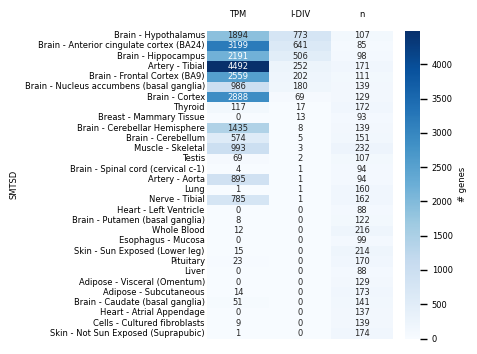

In [162]:
def count_sig(df, label):
    sig = df[df.fdr < 0.05].groupby('SMTSD').size().rename(f'{label}').to_frame()
    return sig

hm_count_sp = (
    count_sig(smtsd_spearmanr_tpm, 'TPM')
    .join(count_sig(smtsd_spearmanr_div, 'I-DIV'), how='outer')
    .reindex(smtsd_spearmanr_tpm.SMTSD.unique())
    .fillna(0).astype(int)
    .join(metadata.SMTSD.value_counts().rename('n'))
)
fig, ax = plt.subplots(figsize=(3,4))
sns.heatmap(hm_count_sp.loc[hm_count_sp['n'] > 75].sort_values('I-DIV', ascending=False).astype(int),annot=True, fmt='d', cmap='Blues', cbar_kws={'label': '# genes'})
ax.xaxis.tick_top()
ax.tick_params(left=False, bottom=False, top=False) 
# ax.set_xticklabels(ax.get_xticklabels(),y=1)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)

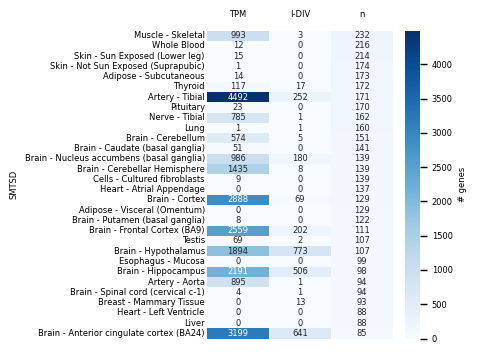

In [ ]:
def count_sig(df, label):
    sig = df[df.fdr < 0.05].groupby('SMTSD').size().rename(f'{label}').to_frame()
    return sig

hm_count_sp = (
    count_sig(smtsd_spearmanr_tpm, 'TPM')
    .join(count_sig(smtsd_spearmanr_div, 'I-DIV'), how='outer')
    .reindex(smtsd_spearmanr_tpm.SMTSD.unique())
    .fillna(0).astype(int)
    .join(metadata.SMTSD.value_counts().rename('n'))
)
fig, ax = plt.subplots(figsize=(3,4))
sns.heatmap(hm_count_sp.loc[hm_count_sp['n'] > 75].sort_values('n', ascending=False).astype(int),annot=True, fmt='d', cmap='Blues', cbar_kws={'label': '# genes'})
ax.xaxis.tick_top()
ax.tick_params(left=False, bottom=False, top=False) 
# ax.set_xticklabels(ax.get_xticklabels(),y=1)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
fig.savefig('figs_lme/spearmanr/hm.png', format='png', dpi=300, bbox_inches='tight')

In [ ]:
hm_count = pd.DataFrame(index=smtsd_spearmanr_tpm.SMTSD.unique())
hm_count = hm_count.join(smtsd_spearmanr_tpm.loc[smtsd_spearmanr_tpm.fdr < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'TPM AGE'}).join(smtsd_spearmanr_div.loc[smtsd_spearmanr_div.fdr < 0.05].groupby('SMTSD').size().to_frame().rename(columns={0:'I-DIV AGE'})))
hm_count = hm_count.join(pd.Series(metadata.SMTSD.value_counts(), name = 'n'))
hm_count

,TPM AGE,I-DIV AGE,n
Artery - Aorta,895.0,1.0,94
Uterus,NaN,NaN,18
Esophagus - Mucosa,NaN,NaN,99
Brain - Cortex,2888.0,69.0,129
Muscle - Skeletal,993.0,3.0,232
Brain - Anterior cingulate cortex (BA24),3199.0,641.0,85
Skin - Sun Exposed (Lower leg),15.0,NaN,214
Vagina,NaN,NaN,17
Adrenal Gland,1.0,NaN,36
Whole Blood,12.0,NaN,216


<Axes: >

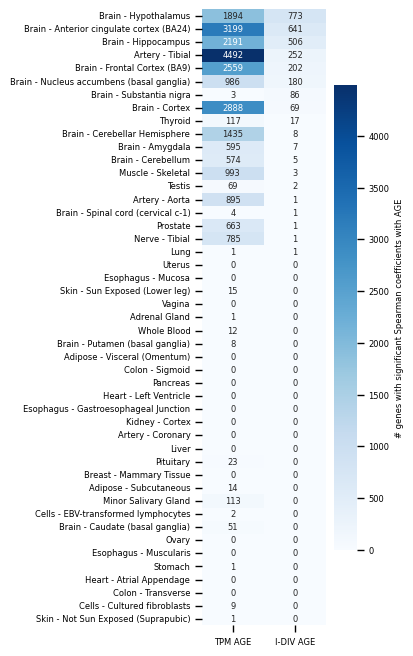

In [ ]:
fig, ax = plt.subplots(figsize=(2,8))
sns.heatmap(hm_count.filter(like='AGE').sort_values('I-DIV AGE', ascending=False).fillna(0).astype(int), annot=True, fmt='d', cmap='Blues', cbar_kws={'label': '# genes with significant Spearman coefficients with AGE'})

In [ ]:
age_spearman_div = smtsd_spearmanr_div.loc[smtsd_spearmanr_div.SMTSD == 'Brain - Substantia nigra'].set_index('Unnamed: 0')
age_spearman_div = age_spearman_div.join(gene_info.gene_name)
age_spearman_div

,coef,p_val,SMTSD,fdr,gene_name
Unnamed: 0,,,,,
ENSG00000000419,0.358440,0.003369,Brain - Substantia nigra,0.099291,DPM1
ENSG00000000457,-0.206394,0.099040,Brain - Substantia nigra,0.410968,SCYL3
ENSG00000000460,-0.221252,0.076527,Brain - Substantia nigra,0.368586,C1orf112
ENSG00000000938,-0.009601,0.939494,Brain - Substantia nigra,0.980902,FGR
ENSG00000000971,0.192361,0.124748,Brain - Substantia nigra,0.445487,CFH
...,...,...,...,...,...
ENSG00000283683,0.099616,0.429814,Brain - Substantia nigra,0.745398,RP3-454G6.2
ENSG00000283703,NaN,NaN,Brain - Substantia nigra,NaN,RP11-680F20.6
ENSG00000283992,0.189251,0.131077,Brain - Substantia nigra,0.455198,LYNX1


In [ ]:
sn_enrichr = pd.concat([do_enrichr(gene_list=age_spearman_div.loc[(age_spearman_div.fdr < 0.05) & (age_spearman_div.coef < 0), 'gene_name'].to_list(), background_genelist=age_spearman_div.loc[:, 'gene_name'].to_list(), trend='-'),
                        do_enrichr(gene_list=age_spearman_div.loc[(age_spearman_div.fdr < 0.05) & (age_spearman_div.coef > 0), 'gene_name'].to_list(), background_genelist=age_spearman_div.loc[:, 'gene_name'].to_list(), trend='+')])

In [14]:
spearman_div_coef = smtsd_spearmanr_div.loc[smtsd_spearmanr_div.SMTSD.str.contains('Brain')].pivot(index = 'Unnamed: 0', columns = 'SMTSD', values= 'coef')
spearman_div_fdr =smtsd_spearmanr_div.loc[smtsd_spearmanr_div.SMTSD.str.contains('Brain')].pivot(index = 'Unnamed: 0', columns = 'SMTSD', values= 'fdr')

In [15]:
chooscols = spearman_div_fdr[spearman_div_fdr < 0.05].count(axis='rows')[spearman_div_fdr[spearman_div_fdr < 0.05].count(axis='rows') > 0].index
sign_fdrs = spearman_div_fdr[spearman_div_fdr < 0.05]
sign_fdrs = sign_fdrs[chooscols]
sign_fdrs = sign_fdrs.loc[sign_fdrs.count(axis='columns')[sign_fdrs.count(axis='columns') > 1].index]
sign_fdrs = sign_fdrs.assign(countvals = sign_fdrs.count(axis='columns'))


sign_coefs = spearman_div_coef.loc[sign_fdrs.index, sign_fdrs.drop(columns='countvals').columns ]
sign_coefs = sign_coefs[~sign_fdrs.drop(columns='countvals').isna()]
sign_coefs = sign_coefs.copy()
sign_coefs['n_above_0'] = (sign_coefs > 0).sum(axis=1)
sign_coefs['n_below_0'] = (sign_coefs < 0).sum(axis=1)

sign_coefs[['n_above_0', 'n_below_0']]


SMTSD,n_above_0,n_below_0
Unnamed: 0,,
ENSG00000002330,0,2
ENSG00000004777,0,2
ENSG00000005206,0,2
ENSG00000005379,0,2
ENSG00000006007,0,2
...,...,...
ENSG00000250510,0,2
ENSG00000265491,2,0
ENSG00000266338,0,3


In [16]:
sign_coefs.loc[(sign_coefs.n_above_0 == 1) & (sign_coefs.n_below_0 == 1),['n_above_0', 'n_below_0']]

SMTSD,n_above_0,n_below_0
Unnamed: 0,,
ENSG00000171798,1,1


In [17]:
sign_coefs.loc['ENSG00000171798']

SMTSD
Brain - Amygdala                                  NaN
Brain - Anterior cingulate cortex (BA24)    -0.338089
Brain - Cerebellar Hemisphere                     NaN
Brain - Cerebellum                                NaN
Brain - Cortex                                    NaN
Brain - Frontal Cortex (BA9)                      NaN
Brain - Hippocampus                               NaN
Brain - Hypothalamus                         0.301563
Brain - Nucleus accumbens (basal ganglia)         NaN
Brain - Spinal cord (cervical c-1)                NaN
Brain - Substantia nigra                          NaN
n_above_0                                    1.000000
n_below_0                                    1.000000
Name: ENSG00000171798, dtype: float64

In [18]:
sign_fdrs.loc['ENSG00000171798']

SMTSD
Brain - Amygdala                                  NaN
Brain - Anterior cingulate cortex (BA24)     0.044538
Brain - Cerebellar Hemisphere                     NaN
Brain - Cerebellum                                NaN
Brain - Cortex                                    NaN
Brain - Frontal Cortex (BA9)                      NaN
Brain - Hippocampus                               NaN
Brain - Hypothalamus                         0.040184
Brain - Nucleus accumbens (basal ganglia)         NaN
Brain - Spinal cord (cervical c-1)                NaN
Brain - Substantia nigra                          NaN
countvals                                    2.000000
Name: ENSG00000171798, dtype: float64

** counts **
n 20-49: 14
n 50-59: 25
n 60-79: 46
r = -0.34,fdr = 0.04 
        


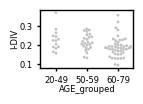

In [ ]:
gid = 'ENSG00000171798'; subt = 'Brain - Anterior cingulate cortex (BA24)'

gn = gene_info.loc['ENSG00000171798', 'gene_name']
if os.path.isdir(pth +'figs_lme/' + '/spearmanr/' + gn) ==False:
    os.mkdir(pth +'figs_lme/' + '/spearmanr/' + gn)
plotdf = make_swarmplot_df(subt=subt, gene=gn)
isoforms_df = get_isoforms_from_gene(gene = gn)

fig, ax = plt.subplots(figsize=(1.2, 0.75))
sns.swarmplot(data=plotdf, x='AGE_grouped', y=gn, order=['20-49', '50-59', '60-79'], c = 'silver', s=2, edgecolor='None')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)
ax.set_ylabel('I-DIV')
s = f'''** counts **
n 20-49: {len(plotdf.loc[plotdf.AGE_grouped == '20-49', gn])}
n 50-59: {len(plotdf.loc[plotdf.AGE_grouped == '50-59', gn])}
n 60-79: {len(plotdf.loc[plotdf.AGE_grouped == '60-79', gn])}
r = {sign_coefs.loc['ENSG00000171798', subt]:.2f},fdr = {sign_fdrs.loc['ENSG00000171798', subt]:.2f} 
        ''' 
fig.savefig(pth +'figs_lme/' + 'spearmanr/' + gn + '/Anterior_cingulate_cortex.swarmplot.png', format='png', dpi=300, bbox_inches='tight')
print(s)

with open(pth +'figs_lme/' + 'spearmanr/' + gn + '/Anterior_cingulate_cortex.' + 'about.txt', 'w') as f:
    f.write(s)
    f.close()

isoform_expression_barplots(gene=gn,isoforms_df=isoforms_df, subt=subt, savefig=True, path_and_name =pth + 'figs_lme/spearmanr/' +  gn + '/Anterior_cingulate_cortex.barplot')
isoform_meanexpression_lineplot(isoforms_df,subt, savefig=True, path_and_name = pth + 'figs_lme/spearmanr/' + gn + '/Anterior_cingulate_cortex.lineplot')

** counts **
n 20-49: 14
n 50-59: 37
n 60-79: 56
r = 0.30,fdr = 0.04 
        


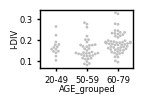

In [ ]:
gid = 'ENSG00000171798'; subt = 'Brain - Hypothalamus'

gn = gene_info.loc['ENSG00000171798', 'gene_name']
if os.path.isdir(pth +'figs_lme/' + '/spearmanr/' + gn) ==False:
    os.mkdir(pth +'figs_lme/' + '/spearmanr/' + gn)
plotdf = make_swarmplot_df(subt=subt, gene=gn)
isoforms_df = get_isoforms_from_gene(gene = gn)

fig, ax = plt.subplots(figsize=(1.2, 0.75))
sns.swarmplot(data=plotdf, x='AGE_grouped', y=gn, order=['20-49', '50-59', '60-79'], c = 'silver', s=2, edgecolor='None')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)
ax.set_ylabel('I-DIV')
s = f'''** counts **
n 20-49: {len(plotdf.loc[plotdf.AGE_grouped == '20-49', gn])}
n 50-59: {len(plotdf.loc[plotdf.AGE_grouped == '50-59', gn])}
n 60-79: {len(plotdf.loc[plotdf.AGE_grouped == '60-79', gn])}
r = {sign_coefs.loc[gid, subt]:.2f},fdr = {sign_fdrs.loc[gid, subt]:.2f} 
        ''' 
fig.savefig(pth +'figs_lme/' + 'spearmanr/' + gn + '/Hypothalamus.swarmplot.png', format='png', dpi=300, bbox_inches='tight')
print(s)
with open(pth +'figs_lme/' + 'spearmanr/' + gn + '/Hypothalamus.' + 'about.txt', 'w') as f:
    f.write(s)
    f.close()

isoform_expression_barplots(gene=gn,isoforms_df=isoforms_df, subt=subt, savefig=True, path_and_name =pth + 'figs_lme/spearmanr/' + gn + '/Hypothalamus.barplot')
isoform_meanexpression_lineplot(isoforms_df,subt, savefig=True, path_and_name = pth + 'figs_lme/spearmanr/' + gn + '/Hypothalamus.lineplot')

# counts for text

In [ ]:
tissues_dirs = [f.split('.')[0] for f in os.listdir(multiple_linear_regression_path + 'SMTSD/') if f.endswith('.limma.tpm.coefficients.csv.gz')]
smtsd_limma_tpm = pd.concat([pd.read_csv(multiple_linear_regression_path + f'SMTSD/{t}.limma.tpm.coefficients.csv.gz') for t in tissues_dirs])
smtsd_limma_div = pd.concat([pd.read_csv(multiple_linear_regression_path + f'SMTSD/{t}.limma.div.coefficients.csv.gz') for t in tissues_dirs])

smtsd_limma_tpm = smtsd_limma_tpm[['gene', 'tissue', 'n_samples'] + ['age_int_coef', 'age_int_SE', 'age_int_t', 'age_int_p', 'age_int_FDR']].rename(columns={'tissue': 'SMTSD'})
smtsd_limma_div = smtsd_limma_div[['gene', 'tissue', 'n_samples'] + ['age_int_coef', 'age_int_SE', 'age_int_t', 'age_int_p', 'age_int_FDR']].rename(columns={'tissue': 'SMTSD'})

tissues_dirs = [f.split('.')[0] for f in os.listdir(spearman_path + 'SMTSD/') if f.endswith('.spearmanr.tpm.csv.gz')]

smtsd_spearmanr_tpm = pd.concat([pd.read_csv(spearman_path + f'SMTSD/{t}.spearmanr.tpm.csv.gz').assign(SMTSD=t) for t in tissues_dirs])
smtsd_spearmanr_div = pd.concat([pd.read_csv(spearman_path + f'SMTSD/{t}.spearmanr.div.csv.gz').assign(SMTSD=t) for t in tissues_dirs])
smtsd_spearmanr_tpm['fdr'] = (smtsd_spearmanr_tpm.groupby('SMTSD')['p_val'].transform(lambda p: correct_pvalues_with_nan(p, method='fdr_bh', alpha=0.05)[1]))
smtsd_spearmanr_div['fdr'] = (smtsd_spearmanr_div.groupby('SMTSD')['p_val'].transform(lambda p: correct_pvalues_with_nan(p, method='fdr_bh', alpha=0.05)[1]))


''' filter STMSDs for more than 75 samples '''
SMTSD_many_samples = metadata.SMTSD.value_counts()[metadata.SMTSD.value_counts() > 75].index

smtsd_limma_tpm = smtsd_limma_tpm.loc[smtsd_limma_tpm.SMTSD.isin(SMTSD_many_samples)]
smtsd_limma_div = smtsd_limma_div.loc[smtsd_limma_div.SMTSD.isin(SMTSD_many_samples)]

smtsd_spearmanr_tpm =smtsd_spearmanr_tpm.loc[smtsd_spearmanr_tpm.SMTSD.isin(SMTSD_many_samples)]
smtsd_spearmanr_div =smtsd_spearmanr_div.loc[smtsd_spearmanr_div.SMTSD.isin(SMTSD_many_samples)]

fdrs_tpm_limma = smtsd_limma_tpm.pivot(index = 'gene', columns= 'SMTSD', values='age_int_FDR')
fdrs_div_limma = smtsd_limma_div.pivot(index = 'gene', columns= 'SMTSD', values='age_int_FDR')

In [12]:
smtsd_limma_tpm.rename(columns={col: col.replace('age_int', 'AGE') for col in smtsd_limma_tpm.columns})

,gene,SMTSD,n_samples,AGE_coef,AGE_SE,AGE_t,AGE_p,AGE_FDR
0,ENSG00000187634,Breast - Mammary Tissue,93,0.207670,0.098918,2.099418,0.038571,0.429351
1,ENSG00000188976,Breast - Mammary Tissue,93,0.009844,0.040154,0.245159,0.806890,0.965488
2,ENSG00000187961,Breast - Mammary Tissue,93,-0.094458,0.059706,-1.582044,0.117137,0.590496
3,ENSG00000187583,Breast - Mammary Tissue,93,0.120708,0.119155,1.013026,0.313755,0.784834
4,ENSG00000187642,Breast - Mammary Tissue,93,0.038253,0.074466,0.513693,0.608722,0.911631
...,...,...,...,...,...,...,...,...
15829,ENSG00000008735,Heart - Left Ventricle,88,-0.003994,0.022294,-0.179141,0.858253,0.971527
15830,ENSG00000100299,Heart - Left Ventricle,88,-0.061998,0.049527,-1.251804,0.214076,0.740397
15831,ENSG00000251322,Heart - Left Ventricle,88,-0.153621,0.104070,-1.476134,0.143603,0.699684
15832,ENSG00000100312,Heart - Left Ventricle,88,-0.071765,0.056970,-1.259704,0.211225,0.738670


In [14]:
smtsd_limma_div.rename(columns={col: col.replace('age_int', 'AGE') for col in smtsd_limma_div.columns})

,gene,SMTSD,n_samples,AGE_coef,AGE_SE,AGE_t,AGE_p,AGE_FDR
0,ENSG00000187634,Breast - Mammary Tissue,93,0.019667,0.017190,1.144112,0.255601,0.764046
1,ENSG00000188976,Breast - Mammary Tissue,93,0.010900,0.008491,1.283738,0.202518,0.726661
2,ENSG00000187961,Breast - Mammary Tissue,93,0.000853,0.005556,0.153480,0.878362,0.981800
3,ENSG00000187583,Breast - Mammary Tissue,93,0.011147,0.031980,0.348572,0.728222,0.953223
4,ENSG00000187642,Breast - Mammary Tissue,93,-0.020308,0.027041,-0.750985,0.454614,0.868462
...,...,...,...,...,...,...,...,...
15829,ENSG00000008735,Heart - Left Ventricle,88,0.001024,0.042326,0.024201,0.980749,0.996958
15830,ENSG00000100299,Heart - Left Ventricle,88,0.009927,0.005508,1.802261,0.075028,0.715104
15831,ENSG00000251322,Heart - Left Ventricle,88,0.003129,0.007130,0.438884,0.661852,0.949232
15832,ENSG00000100312,Heart - Left Ventricle,88,0.000972,0.040211,0.024170,0.980773,0.996958


In [18]:
''' supplementary material '''
smtsd_limma_tpm.rename(columns={col: col.replace('age_int', 'AGE') for col in smtsd_limma_tpm.columns}).merge(smtsd_limma_div.rename(columns={col: col.replace('age_int', 'AGE') for col in smtsd_limma_div.columns}), on =['gene', 'SMTSD'], suffixes=('_TPM', '_I-DIV')).to_csv(supplementary_data_path + '4_limma.csv.gz', index=False)
smtsd_spearmanr_tpm.rename(columns={'coef': 'coef_TPM', 'p_val': 'p_val_TPM', 'fdr': 'fdr_TPM'}).merge(smtsd_spearmanr_div.rename(columns={'coef': 'coef_I-DIV', 'p_val': 'p_val_I-DIV', 'fdr': 'fdr_I-DIV'}), on=['Unnamed: 0', 'SMTSD']).to_csv(supplementary_data_path + '4_spearman.csv.gz', index=False)

In [264]:
across_all_tpm_limma = fdrs_tpm_limma[fdrs_tpm_limma < 0.05].count(axis='columns')
across_all_tpm_limma = across_all_tpm_limma[across_all_tpm_limma > 0]
print('TPM all')
len(across_all_tpm_limma)


TPM all


7687

In [265]:
across_all_div_limma = fdrs_div_limma[fdrs_div_limma < 0.05].count(axis='columns')
across_all_div_limma = across_all_div_limma[across_all_div_limma > 0]
print('I-DIV all')
len(across_all_div_limma)


I-DIV all


765

In [266]:
across_brain_tpm_limma = fdrs_tpm_limma.filter(like='Brain')[fdrs_tpm_limma.filter(like='Brain') < 0.05].count(axis='columns')
across_brain_tpm_limma = across_brain_tpm_limma[across_brain_tpm_limma > 0]
print('TPM brain')
len(across_brain_tpm_limma)

TPM brain


4259

In [267]:
across_brain_div_limma = fdrs_div_limma.filter(like='Brain')[fdrs_div_limma.filter(like='Brain') < 0.05].count(axis='columns')
across_brain_div_limma = across_brain_div_limma[across_brain_div_limma > 0]
print('I-DIV brain')
len(across_brain_div_limma)

I-DIV brain


668

In [285]:
f'''Age-associated changes in I-DIV were concentrated in brain regions, which accounted for {round((len(across_brain_div_limma)*100)/len(across_all_div_limma),2)}% ({len(across_brain_div_limma)} of {len(across_all_div_limma)}) significant associations for I-DIV but only {round((len(across_brain_tpm_limma) * 100)/len(across_all_tpm_limma),2)}% ({len(across_brain_tpm_limma)} of {len(across_all_tpm_limma)}) for expression (limma; Spearman: [X] of [X] versus [X] of [X]; FDR < 0.05). 
'''

'Age-associated changes in I-DIV were concentrated in brain regions, which accounted for 87.32% (668 of 765) significant associations for I-DIV but only 55.41% (4259 of 7687) for expression (limma; Spearman: [X] of [X] versus [X] of [X]; FDR < 0.05). \n'

In [228]:
fdrs_tpm_spearman = smtsd_spearmanr_tpm.pivot(index = 'Unnamed: 0', columns= 'SMTSD', values='fdr')
fdrs_div_spearman = smtsd_spearmanr_div.pivot(index = 'Unnamed: 0', columns= 'SMTSD', values='fdr')

In [231]:
across_all_tpm_spearman = fdrs_tpm_spearman[fdrs_tpm_spearman < 0.05].count(axis='columns')
across_all_tpm_spearman = across_all_tpm_spearman[across_all_tpm_spearman > 0]
print('TPM all')
len(across_all_tpm_spearman)


TPM all


10641

In [232]:
across_all_div_spearman = fdrs_div_spearman[fdrs_div_spearman < 0.05].count(axis='columns')
across_all_div_spearman = across_all_div_spearman[across_all_div_spearman > 0]
print('I-DIV all')
len(across_all_div_spearman)


I-DIV all


1992

In [233]:
across_brain_tpm_spearman = fdrs_tpm_spearman.filter(like='Brain')[fdrs_tpm_spearman.filter(like='Brain') < 0.05].count(axis='columns')
across_brain_tpm_spearman = across_brain_tpm_spearman[across_brain_tpm_spearman > 0]
print('TPM brain')
len(across_brain_tpm_spearman)


TPM brain


7512

In [235]:
across_brain_div_spearman = fdrs_div_spearman.filter(like='Brain')[fdrs_div_spearman.filter(like='Brain') < 0.05].count(axis='columns')
across_brain_div_spearman = across_brain_div_spearman[across_brain_div_spearman > 0]
print('I-DIV brain')
len(across_brain_div_spearman)


I-DIV brain


1762

In [287]:
f'''Age-associated changes in I-DIV were concentrated in brain regions, which accounted for {round((len(across_brain_div_limma)*100)/len(across_all_div_limma),2)}% ({len(across_brain_div_limma)} of {len(across_all_div_limma)}) for expression 
(limma; Spearman: {len(across_brain_div_spearman)} of {len(across_all_div_spearman)} versus {len(across_brain_tpm_spearman)} of {len(across_all_tpm_spearman)}; FDR < 0.05). 
'''

'Age-associated changes in I-DIV were concentrated in brain regions, which accounted for 87.32% (668 of 765) for expression \n(limma; Spearman: 1762 of 1992 versus 7512 of 10641; FDR < 0.05). \n'

# Mixed Linear Models across all samples

` y ~ SMTS + SEX + age_int + SMRIN + SMTSISCH ~ 1 | donor`

In [ ]:
lme_smts_tpm = pd.read_csv(lme_path + 'lme_across_SMTS/lme_across_SMTS.lme.tpm.allcoefs.long.csv.gz', index_col='gene')
lme_smts_div = pd.read_csv(lme_path + 'lme_across_SMTS/lme_across_SMTS.lme.div.allcoefs.long.csv.gz', index_col='gene')

lme_smts_tpm['trend'] = lme_smts_tpm.apply(lambda row: categorise_gene_trend(row, m='tpm', fdr_colname='fdr', coef_colname='coef'), axis='columns')
lme_smts_div['trend'] = lme_smts_div.apply(lambda row: categorise_gene_trend(row, m='div', fdr_colname='fdr', coef_colname='coef'), axis='columns')

lme_smts_tpm = lme_smts_tpm.join(gene_info.gene_name)
lme_smts_div = lme_smts_div.join(gene_info.gene_name)

In [29]:
lme_smts_tpm.reset_index().merge(lme_smts_div.reset_index(), on=['gene', 'term'], suffixes=('_TPM', '_I-DIV')).to_csv(source_data_path + '4e_left.csv.gz', index=True)

,gene,term,coef_tpm,se_tpm,df_tpm,t_val_tpm,p_val_tpm,fdr_tpm,trend_tpm,gene_name_tpm,coef_div,se_div,df_div,t_val_div,p_val_div,fdr_div,trend_div,gene_name_div
0,ENSG00000187634,(Intercept),0.859466,0.145910,4521,5.890375,4.132619e-09,4.895331e-09,TPM+,SAMD11,0.490154,0.021993,4521,22.286439,1.758930e-104,3.577049e-104,I-DIV+,SAMD11
1,ENSG00000187634,SMTSAdrenal Gland,0.059497,0.143057,4521,0.415899,6.775036e-01,7.269001e-01,TPM0,SAMD11,0.011568,0.021881,4521,0.528692,5.970452e-01,6.846449e-01,I-DIV0,SAMD11
2,ENSG00000187634,SMTSBlood,-1.851716,0.073738,4521,-25.111947,2.188930e-130,3.947103e-130,TPM-,SAMD11,-0.437513,0.011279,4521,-38.791427,2.059320e-284,8.626263e-283,I-DIV-,SAMD11
3,ENSG00000187634,SMTSBlood Vessel,1.671336,0.065761,4521,25.415401,2.618857e-133,2.599811e-132,TPM+,SAMD11,0.110756,0.010063,4521,11.005994,8.040095e-28,1.032497e-26,I-DIV+,SAMD11
4,ENSG00000187634,SMTSBrain,-0.637826,0.051643,4521,-12.350707,1.727969e-34,2.395015e-34,TPM-,SAMD11,-0.094494,0.007895,4521,-11.968307,1.606942e-32,3.612198e-32,I-DIV-,SAMD11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459181,ENSG00000079974,SMTSVagina,0.804278,0.087358,4521,9.206734,5.023782e-20,5.185565e-19,TPM+,RABL2B,-0.026559,0.009988,4521,-2.658996,7.865010e-03,3.091722e-02,I-DIV-,RABL2B
459182,ENSG00000079974,SEXFemale,-0.003349,0.023826,264,-0.140564,8.883214e-01,9.616902e-01,TPM0,RABL2B,-0.004031,0.001982,264,-2.033641,4.298776e-02,6.028948e-01,I-DIV0,RABL2B
459183,ENSG00000079974,age_int,0.008645,0.013244,264,0.652750,5.144858e-01,7.502641e-01,TPM0,RABL2B,0.000299,0.001096,264,0.272852,7.851804e-01,9.348202e-01,I-DIV0,RABL2B
459184,ENSG00000079974,SMRIN,-0.027171,0.006961,4521,-3.903195,9.631311e-05,1.280347e-04,TPM-,RABL2B,0.002210,0.000787,4521,2.808902,4.992422e-03,6.708818e-03,I-DIV+,RABL2B


In [28]:
lme_smts_div.reset_index()

,gene,term,coef,se,df,t_val,p_val,fdr,trend,gene_name
0,ENSG00000187634,(Intercept),0.490154,0.021993,4521,22.286439,1.758930e-104,3.577049e-104,I-DIV+,SAMD11
1,ENSG00000187634,SMTSAdrenal Gland,0.011568,0.021881,4521,0.528692,5.970452e-01,6.846449e-01,I-DIV0,SAMD11
2,ENSG00000187634,SMTSBlood,-0.437513,0.011279,4521,-38.791427,2.059320e-284,8.626263e-283,I-DIV-,SAMD11
3,ENSG00000187634,SMTSBlood Vessel,0.110756,0.010063,4521,11.005994,8.040095e-28,1.032497e-26,I-DIV+,SAMD11
4,ENSG00000187634,SMTSBrain,-0.094494,0.007895,4521,-11.968307,1.606942e-32,3.612198e-32,I-DIV-,SAMD11
...,...,...,...,...,...,...,...,...,...,...
459181,ENSG00000079974,SMTSVagina,-0.026559,0.009988,4521,-2.658996,7.865010e-03,3.091722e-02,I-DIV-,RABL2B
459182,ENSG00000079974,SEXFemale,-0.004031,0.001982,264,-2.033641,4.298776e-02,6.028948e-01,I-DIV0,RABL2B
459183,ENSG00000079974,age_int,0.000299,0.001096,264,0.272852,7.851804e-01,9.348202e-01,I-DIV0,RABL2B
459184,ENSG00000079974,SMRIN,0.002210,0.000787,4521,2.808902,4.992422e-03,6.708818e-03,I-DIV+,RABL2B


## compare coefficients

In [ ]:
if not os.path.isdir('figs_lme/compare_coeffs/'):
    os.mkdir('figs_lme/compare_coeffs/')

In [31]:
lme_smts_tpm.loc[lme_smts_tpm.term == 'age_int',['coef', 'fdr']].add_suffix('_tpm').join(lme_smts_div.loc[lme_smts_div.term == 'age_int',['coef', 'fdr']].add_suffix('_div'))

,coef_tpm,fdr_tpm,coef_div,fdr_div
gene,,,,
ENSG00000187634,0.067637,0.027784,0.006651,0.251181
ENSG00000188976,0.010619,0.583051,0.001430,0.745748
ENSG00000187961,0.008443,0.886120,0.000157,0.979239
ENSG00000187583,0.016689,0.644966,0.009464,0.352800
ENSG00000187642,-0.014258,0.650367,-0.007749,0.483063
...,...,...,...,...
ENSG00000008735,-0.005367,0.868005,-0.001045,0.957044
ENSG00000100299,0.020377,0.527834,-0.000294,0.957044
ENSG00000251322,-0.055630,0.040528,-0.003712,0.365909


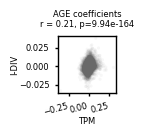

In [ ]:
plotdf = lme_smts_tpm.loc[lme_smts_tpm.term == 'age_int',['coef', 'fdr']].add_suffix('_tpm').join(lme_smts_div.loc[lme_smts_div.term == 'age_int',['coef', 'fdr']].add_suffix('_div'))
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf, x='coef_tpm', y='coef_div', alpha=0.05, color='dimgrey', edgecolor='None', s=5)
r, p = st.pearsonr(plotdf.coef_tpm, plotdf.coef_div)
ax.set(title = 'AGE coefficients' + '\n' + f'r = {r:.2f}, {annotpval(p)}', xlabel='TPM', ylabel='I-DIV')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='right', rotation=15, y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)
fig.savefig('figs_lme/compare_coeffs/SMTS.AGE.png', dpi=300, bbox_inches='tight')
plotdf.to_csv(source_data_path + 'S5d_top.csv.gz',index=True)

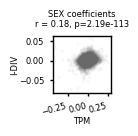

In [ ]:
plotdf = lme_smts_tpm.loc[lme_smts_tpm.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_tpm').join(lme_smts_div.loc[lme_smts_div.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_div'))
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf, x='coef_tpm', y='coef_div', alpha=0.05, color='dimgrey', edgecolor='None', s=5)
r, p = st.pearsonr(plotdf.coef_tpm, plotdf.coef_div)
ax.set(title = 'SEX coefficients' + '\n' + f'r = {r:.2f}, {annotpval(p)}', xlabel='TPM', ylabel='I-DIV')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='right', rotation=15, y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)
fig.savefig('figs_lme/compare_coeffs/SMTS.SEX.png', dpi=300, bbox_inches='tight')
plotdf.to_csv(source_data_path + 'S5d_bottom.csv.gz',index=True)

In [ ]:
def count_gene_significantcoeffs(plotdf, titlestr,filename=''):
    fig, ax = plt.subplots(figsize=(0.75,0.75))

    sns.scatterplot(data = plotdf, x='coef_AGE', y='coef_SEX', alpha=0.2, color='silver', edgecolor='None', s=5)
    sns.scatterplot(data = plotdf.loc[plotdf.fdr_AGE < 0.05], x='coef_AGE', y='coef_SEX', alpha=1, color='Royalblue', edgecolor='None', s=5)
    sns.scatterplot(data = plotdf.loc[plotdf.fdr_SEX < 0.05], x='coef_AGE', y='coef_SEX', alpha=1, color='Gold', edgecolor='None', s=5)
    sns.scatterplot(data = plotdf.loc[(plotdf.fdr_SEX < 0.05) & (plotdf.fdr_AGE < 0.05)], x='coef_AGE', y='coef_SEX', alpha=1, color='limegreen', edgecolor='None', s=5)
    ax.set_title(titlestr)

    ax.tick_params(length=2.5)
    ax.set_yticklabels(ax.get_yticklabels(),x=0)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right', y=0)
    ax.set_xlabel(ax.get_xlabel(), labelpad=0)
    ax.set_ylabel(ax.get_ylabel(), labelpad=0)    
    
    ax.set_xticklabels(ax.get_xticklabels(), ha='center')

    ngenes = {}
    ngenes['AGE only'] = len(plotdf.loc[(plotdf.fdr_AGE < 0.05) & (plotdf.fdr_SEX >= 0.05)])
    ngenes['SEX only'] = len(plotdf.loc[(plotdf.fdr_SEX < 0.05) & (plotdf.fdr_AGE >= 0.05)])
    ngenes['Both'] = len(plotdf.loc[(plotdf.fdr_SEX < 0.05) & (plotdf.fdr_AGE < 0.05)])
    ngenes['Neither'] = len(plotdf.loc[(plotdf.fdr_SEX >= 0.05) & (plotdf.fdr_AGE >= 0.05)])

    s = f'''{titlestr}
    # significant genes AGE: {ngenes['AGE only']}
    # significant genes SEX: {ngenes['SEX only']}
    # significant genes Both: {ngenes['Both']}
    # significant genes Neither: {ngenes['Neither']}
    '''

    print(s)
    
    
    
    if len(filename) > 1:
        
        if not os.path.isdir(pth + 'figs_lme/compare_coeffs/'):
            os.mkdir(pth + 'figs_lme/compare_coeffs/')
        
        with open(pth + 'figs_lme/compare_coeffs/' + filename + '.txt', 'w') as f:
            f.write(s)
            f.close()
        fig.savefig(pth + 'figs_lme/compare_coeffs/' + filename + '.png', dpi=300, bbox_inches='tight')

I-DIV
    # significant genes AGE: 131
    # significant genes SEX: 9
    # significant genes Both: 0
    # significant genes Neither: 15694
    
TPM
    # significant genes AGE: 817
    # significant genes SEX: 240
    # significant genes Both: 41
    # significant genes Neither: 14736
    


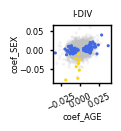

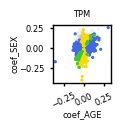

In [ ]:
plotdf = lme_smts_div.loc[lme_smts_div.term == 'age_int',['coef', 'fdr']].add_suffix('_AGE').join(lme_smts_div.loc[lme_smts_div.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_SEX'))
count_gene_significantcoeffs(plotdf, titlestr='I-DIV', filename='SMTS.div')
plotdf.to_csv(source_data_path + '4e_topleft.csv.gz',index=True)
plotdf = lme_smts_tpm.loc[lme_smts_tpm.term == 'age_int',['coef', 'fdr']].add_suffix('_AGE').join(lme_smts_tpm.loc[lme_smts_tpm.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_SEX'))
count_gene_significantcoeffs(plotdf, titlestr='TPM', filename='SMTS.tpm')
plotdf.to_csv(source_data_path + '4e_botomleft.csv.gz',index=True)

general_trend
TPM0 I-DIV0    14859
TPM- I-DIV0      501
TPM+ I-DIV0      343
TPM0 I-DIV+       74
TPM0 I-DIV-       43
TPM+ I-DIV+        7
TPM- I-DIV-        5
TPM- I-DIV+        2
Name: count, dtype: int64

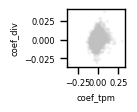

In [ ]:
plotdf = lme_smts_tpm.loc[lme_smts_tpm.term == 'age_int', ['trend', 'coef']].add_suffix('_tpm').join(lme_smts_div.loc[lme_smts_div.term == 'age_int', ['trend', 'coef']].add_suffix('_div'))
plotdf['general_trend'] = plotdf['trend_tpm'] + ' ' + plotdf['trend_div']

fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf, x = 'coef_tpm', y = 'coef_div', color = 'silver', edgecolor='None', alpha = 0.2, s = 5)
plotdf.general_trend.value_counts()

## compare with Melé 2015

In [ ]:
mele_tissues = ['Adipose - Subcutaneous', 'Artery - Tibial', 'Heart - Left Ventricle', 'Lung', 'Muscle - Skeletal','Nerve - Tibial', 'Skin - Sun Exposed (Lower leg)', 'Thyroid', 'Whole Blood']

In [40]:
AGE_coeff = lme_smts_tpm.loc[lme_smts_tpm.term == 'age_int']
AGE_coeff

,term,coef,se,df,t_val,p_val,fdr,trend,gene_name
gene,,,,,,,,,
ENSG00000187634,age_int,0.067637,0.020178,264,3.352070,0.000919,0.027784,TPM+,SAMD11
ENSG00000188976,age_int,0.010619,0.010174,264,1.043651,0.297601,0.583051,TPM0,NOC2L
ENSG00000187961,age_int,0.008443,0.026591,264,0.317524,0.751097,0.886120,TPM0,KLHL17
ENSG00000187583,age_int,0.016689,0.018512,264,0.901564,0.368111,0.644966,TPM0,PLEKHN1
ENSG00000187642,age_int,-0.014258,0.016064,264,-0.887554,0.375589,0.650367,TPM0,PERM1
...,...,...,...,...,...,...,...,...,...
ENSG00000008735,age_int,-0.005367,0.014870,264,-0.360905,0.718459,0.868005,TPM0,MAPK8IP2
ENSG00000100299,age_int,0.020377,0.017399,264,1.171173,0.242585,0.527834,TPM0,ARSA
ENSG00000251322,age_int,-0.055630,0.017733,264,-3.137105,0.001900,0.040528,TPM-,SHANK3


In [ ]:
from_paper=pd.read_csv(mele2015_S12_path) # table S12
from_paper = from_paper.join(pd.Series(from_paper.gene_id.str.split('.', expand=True)[0], name ='accession_number'))
from_paper.set_index('accession_number', inplace=True)
from_paper = from_paper.join(AGE_coeff[['coef', 'fdr']].add_suffix('_S'))
# from_paper.dropna(inplace=True)

plotdf = from_paper.loc[:, ['gene_name', 'corrected.pval', 'regression coefficient', 'coef_S', 'fdr_S']].dropna()
plotdf

,gene_name,corrected.pval,regression coefficient,coef_S,fdr_S
accession_number,,,,,
ENSG00000000419,DPM1,0.005017,-0.005537,0.011941,0.518071
ENSG00000000971,CFH,0.002471,0.011451,0.084404,0.017511
ENSG00000002919,SNX11,0.025054,-0.004724,-0.031836,0.037942
ENSG00000002933,TMEM176A,0.003581,0.017831,0.103736,0.063337
ENSG00000003056,M6PR,0.033940,-0.004254,0.003325,0.876808
...,...,...,...,...,...
ENSG00000253910,PCDHGB2,0.002753,0.007081,0.063314,0.000034
ENSG00000255112,CHMP1B,0.005123,-0.006805,0.013878,0.671898
ENSG00000256591,RP11-286N22.8,0.027196,-0.014695,0.003077,0.781722


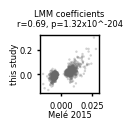

In [42]:
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf, x = 'regression coefficient', y = 'coef_S', edgecolor='None',alpha = 0.3, s = 3, color='dimgrey')
r, p = st.pearsonr(plotdf.loc[:, 'regression coefficient'], plotdf.loc[:, 'coef_S'])
ax.set(xlabel = 'Melé 2015', ylabel = 'this study', title = 'LMM coefficients\n'  + f'r={r:.2f}, {annotpval(p).replace('e', 'x10^')}')
style_axis(ax)

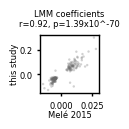

In [ ]:
# plotdf = plotdf.loc[plotdf.fdr_S < 0.05]
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf.loc[plotdf.fdr_S < 0.05], x = 'regression coefficient', y = 'coef_S', edgecolor='None',alpha = 0.3, s = 3, color='dimgrey')
r, p = st.pearsonr(plotdf.loc[plotdf.fdr_S < 0.05, 'regression coefficient'], plotdf.loc[plotdf.fdr_S < 0.05, 'coef_S'])
ax.set(xlabel = 'Melé 2015', ylabel = 'this study', title = 'LMM coefficients\n'  + f'r={r:.2f}, {annotpval(p).replace('e', 'x10^')}')
style_axis(ax)
fig.savefig('figs_lme/compare_coeffs/Mele_Shanas.png', dpi=300, bbox_inches='tight')

s = f''' n = {len(plotdf.loc[plotdf.fdr_S < 0.05, 'regression coefficient'])}
r = {r:.2f}, {annotpval(p)}
'''
print(s)
with open('figs_lme/compare_coeffs/Mele_Shanas.about.txt', 'w') as f:
    f.write(s)
    f.close()

plotdf.loc[plotdf.fdr_S < 0.05].to_csv(source_data_path + 'S5c_bottom.csv.gz', compression='gzip')

### compare our LMM without RIN & ischemic time with Melé 2015  
technical covariates excluded

In [ ]:
lmm_technical_cov_excluded = pd.read_csv(lmm_technical_cov_excluded_path, index_col='gene')
lmm_technical_cov_excluded = lmm_technical_cov_excluded[['fdr.age_int', 'coef.age_int']]
lmm_technical_cov_excluded.rename(columns={'coef.age_int':'coef', 'fdr.age_int': 'fdr'}, inplace=True)

from_paper=pd.read_csv(mele2015_S12_path) # table S12
from_paper = from_paper.join(pd.Series(from_paper.gene_id.str.split('.', expand=True)[0], name ='accession_number'))
from_paper.set_index('accession_number', inplace=True)
from_paper = from_paper.join(lmm_technical_cov_excluded[['coef', 'fdr']].add_suffix('_S'))

 n = 424
r = 0.94, p=p=2.63e-197



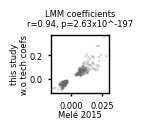

In [ ]:
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf.loc[plotdf.fdr_S < 0.05], x = 'regression coefficient', y = 'coef_S', edgecolor='None',alpha = 0.3, s = 3, color='dimgrey')
r, p = st.pearsonr(plotdf.loc[plotdf.fdr_S < 0.05, 'regression coefficient'], plotdf.loc[plotdf.fdr_S < 0.05, 'coef_S'])
# ax.set(xlabel = 'Melé 2015', ylabel = f'this study\nw.o tech coefs', title = 'LMM coefficients\n'  + f'r={r:.2f}, p={format_small_number(p).replace('e', 'x10^')}')
ax.set(xlabel = 'Melé 2015', ylabel = f'this study\nw.o tech coefs', title = 'LMM coefficients\n'  + f'r={r:.2f}, {annotpval(p).replace('e', 'x10^')}')
style_axis(ax)
fig.savefig('figs_lme/compare_coeffs/Mele_Shanas.wo_tech_coeffs.png', dpi=300, bbox_inches='tight')
s = f''' n = {len(plotdf.loc[plotdf.fdr_S < 0.05, 'regression coefficient'])}
r = {r:.2f}, {annotpval(p)}
'''
print(s)
with open('figs_lme/compare_coeffs/Mele_Shanas.wo_tech_coeffs.about.txt', 'w') as f:
    f.write(s)
    f.close()
plotdf.loc[plotdf.fdr_S < 0.05].to_csv(source_data_path + 'S5c_top.csv.gz', compression='gzip')

In [ ]:
# plotdf = from_paper.loc[:, ['gene_name', 'corrected.pval', 'regression coefficient', 'coef_S', 'fdr_S']].dropna()
# fig, ax = plt.subplots(figsize=(0.75,0.75))
# sns.scatterplot(data = plotdf, x = 'regression coefficient', y = 'coef_S', edgecolor='None',alpha = 0.3, s = 3, color='dimgrey')
# r, p = st.pearsonr(plotdf.loc[:, 'regression coefficient'], plotdf.loc[:, 'coef_S'])
# ax.set(xlabel = 'Melé 2015', ylabel = 'this study', title = 'LMM coefficients\n'  + f'r={r:.2f}, {format_small_number(p)}')
# style_axis(ax)

# fig.savefig('compare_coeffs/Mele_Shanas.wo_tech_coeffs.all.png', dpi=300, bbox_inches='tight')

# Mixed Linear Models across Brain samples  
`y ~ SMTSD(Brain) + SEX + age_int + SMRIN + SMTSISCH ~ 1 | donor`

In [ ]:
lme_smtsdbrain_tpm = pd.read_csv(lme_path + 'lme_across_brainSMTSD/lme_across_brainSMTSD.lme.tpm.allcoefs.long.csv.gz', index_col='gene')
lme_smtsdbrain_div = pd.read_csv(lme_path + 'lme_across_brainSMTSD/lme_across_brainSMTSD.lme.div.allcoefs.long.csv.gz', index_col='gene')

lme_smtsdbrain_tpm['trend'] = lme_smtsdbrain_tpm.apply(lambda row: categorise_gene_trend(row, m='tpm', fdr_colname='fdr', coef_colname='coef'), axis='columns')
lme_smtsdbrain_div['trend'] = lme_smtsdbrain_div.apply(lambda row: categorise_gene_trend(row, m='div', fdr_colname='fdr', coef_colname='coef'), axis='columns')

In [37]:
lme_smtsdbrain_tpm.reset_index().merge(lme_smtsdbrain_div.reset_index(), on=['gene', 'term'], suffixes=('_TPM', '_I-DIV')).to_csv(supplementary_data_path + '4e_right_S5e.csv.gz', index=True)

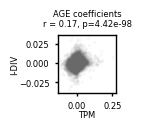

In [ ]:
plotdf = lme_smtsdbrain_tpm.loc[lme_smtsdbrain_tpm.term == 'age_int',['coef', 'fdr']].add_suffix('_tpm').join(lme_smtsdbrain_div.loc[lme_smtsdbrain_div.term == 'age_int',['coef', 'fdr']].add_suffix('_div'))
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf, x='coef_tpm', y='coef_div', alpha=0.05, color='dimgrey', edgecolor='None', s=5)
r, p = st.pearsonr(plotdf.coef_tpm, plotdf.coef_div)
ax.set(title = 'AGE coefficients' + '\n' + f'r = {r:.2f}, {annotpval(p)}', xlabel='TPM', ylabel='I-DIV')
style_axis(ax)
fig.savefig('figs_lme/compare_coeffs/SMTSDbrain.AGE.png', dpi=300, bbox_inches='tight')
plotdf.to_csv(source_data_path + 'S5e_top.csv.gz', compression='gzip', index=False)

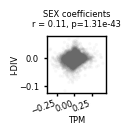

In [ ]:
plotdf = lme_smtsdbrain_tpm.loc[lme_smtsdbrain_tpm.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_tpm').join(lme_smtsdbrain_div.loc[lme_smtsdbrain_div.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_div'))
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf, x='coef_tpm', y='coef_div', alpha=0.05, color='dimgrey', edgecolor='None', s=5)
r, p = st.pearsonr(plotdf.coef_tpm, plotdf.coef_div)
ax.set(title = 'SEX coefficients' + '\n' + f'r = {r:.2f}, {annotpval(p)}', xlabel='TPM', ylabel='I-DIV')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='right', rotation=20, y=0.05)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)
fig.savefig('figs_lme/compare_coeffs/SMTSDbrain.SEX.png', dpi=300, bbox_inches='tight')
plotdf.to_csv(source_data_path + 'S5e_bottom.csv.gz', compression='gzip', index=False)

I-DIV
    # significant genes AGE: 1021
    # significant genes SEX: 5
    # significant genes Both: 0
    # significant genes Neither: 14808
    
TPM
    # significant genes AGE: 3480
    # significant genes SEX: 40
    # significant genes Both: 16
    # significant genes Neither: 12298
    


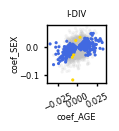

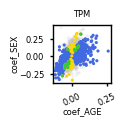

In [ ]:
plotdf = lme_smtsdbrain_div.loc[lme_smtsdbrain_div.term == 'age_int',['coef', 'fdr']].add_suffix('_AGE').join(lme_smtsdbrain_div.loc[lme_smtsdbrain_div.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_SEX'))
count_gene_significantcoeffs(plotdf, titlestr='I-DIV',filename='SMTSDbrain.div')
plotdf.to_csv(source_data_path + '4e_topright.csv.gz',index=True)

plotdf = lme_smtsdbrain_tpm.loc[lme_smtsdbrain_tpm.term == 'age_int',['coef', 'fdr']].add_suffix('_AGE').join(lme_smtsdbrain_tpm.loc[lme_smtsdbrain_tpm.term == 'SEXFemale',['coef', 'fdr']].add_suffix('_SEX'))
count_gene_significantcoeffs(plotdf, titlestr='TPM',filename='SMTSDbrain.tpm')
plotdf.to_csv(source_data_path + '4e_botomright.csv.gz',index=True)

### enrichment analysis in groups of genes

general_trend
TPM0 I-DIV0    11634
TPM- I-DIV0     1776
TPM+ I-DIV0     1403
TPM0 I-DIV-      455
TPM0 I-DIV+      249
TPM- I-DIV-      145
TPM+ I-DIV-       66
TPM+ I-DIV+       53
TPM- I-DIV+       53
Name: count, dtype: int64

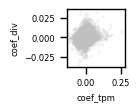

In [15]:
plotdf = lme_smtsdbrain_tpm.loc[lme_smtsdbrain_tpm.term == 'age_int', ['trend', 'coef']].add_suffix('_tpm').join(lme_smtsdbrain_div.loc[lme_smtsdbrain_div.term == 'age_int', ['trend', 'coef']].add_suffix('_div'))
plotdf['general_trend'] = plotdf['trend_tpm'] + ' ' + plotdf['trend_div']

fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = plotdf, x = 'coef_tpm', y = 'coef_div', color = 'silver', edgecolor='None', alpha = 0.2, s = 5)
plotdf.general_trend.value_counts()

In [17]:
plotdf = plotdf.join(gene_info.gene_name)
plotdf

,trend_tpm,coef_tpm,trend_div,coef_div,general_trend,gene_name
gene,,,,,,
ENSG00000187634,TPM0,0.006275,I-DIV0,-0.001009,TPM0 I-DIV0,SAMD11
ENSG00000188976,TPM0,0.000936,I-DIV0,0.001874,TPM0 I-DIV0,NOC2L
ENSG00000187961,TPM0,0.011797,I-DIV0,0.000721,TPM0 I-DIV0,KLHL17
ENSG00000187583,TPM0,0.008240,I-DIV0,0.003710,TPM0 I-DIV0,PLEKHN1
ENSG00000187642,TPM0,-0.000761,I-DIV0,-0.005444,TPM0 I-DIV0,PERM1
...,...,...,...,...,...,...
ENSG00000008735,TPM0,0.001906,I-DIV0,0.002207,TPM0 I-DIV0,MAPK8IP2
ENSG00000100299,TPM0,0.018350,I-DIV0,0.000045,TPM0 I-DIV0,ARSA
ENSG00000251322,TPM0,-0.005454,I-DIV0,0.000797,TPM0 I-DIV0,SHANK3


In [ ]:
enrichr = pd.concat([do_enrichr(gene_list = plotdf.loc[plotdf['general_trend'] == t, 'gene_name'].to_list(), background_genelist = plotdf.loc[:, 'gene_name'].to_list(), trend = t) for t in plotdf['general_trend'].unique()])
enrichr.to_csv(pth + 'tables_lme/' + 'enrichr.SMTSDbrain.csv.gz', index=True)

if os.path.isdir('figs_lme/GO_Biological_Process/') == False:
    os.mkdir('figs_lme/GO_Biological_Process/')

enrichr = enrichr.loc[(enrichr.Gene_set == 'GO_Biological_Process_2025') & (enrichr['Adjusted P-value'] < 0.05)]
enrichr.reset_index(inplace=True)

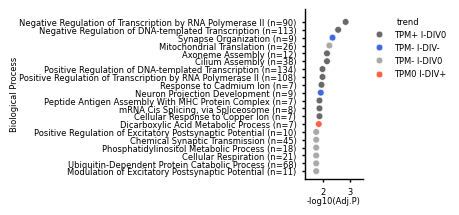

In [ ]:

fig, ax = plt.subplots(figsize=(0.75,2.2))
sns.scatterplot(data = enrichr.sort_values('Adjusted P-value', ascending=True).head(20), x = '-log10(Adjusted P-value)', y = 'Term', hue = 'trend', palette={'TPM0 I-DIV+': 'tomato', 'TPM- I-DIV-': 'royalblue', 'TPM+ I-DIV0': 'dimgrey', 'TPM- I-DIV0': 'darkgrey', 'TPM0 I-DIV0':'silver'})
labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
labels = [label + f' (n={list(enrichr.loc[enrichr.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr.loc[enrichr.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
ax.set_yticklabels(labels)
ax.set(ylabel='Biological Process', xlabel='-log10(Adj.P)')

ax.legend(bbox_to_anchor = (1,1), title = 'trend', frameon=False)
style_axis(ax) ; sns.despine()
ax.set_xlim(ax.get_xlim()[0] -ax.get_xlim()[0]/2 , ax.get_xlim()[1] * 1.3)
ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1] * 1.7)

fig.savefig(pth + 'figs_lme/' + 'GO_Biological_Process/enrichr.png', dpi=300, bbox_inches='tight')

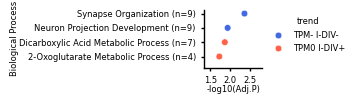

In [ ]:
enrichr = enrichr.loc[(enrichr.Gene_set == 'GO_Biological_Process_2025') & (enrichr['Adjusted P-value'] < 0.05) & (~enrichr.trend.str.contains('I-DIV0'))]
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = enrichr.sort_values('Adjusted P-value', ascending=True), x = '-log10(Adjusted P-value)', y = 'Term', hue = 'trend', palette={'TPM0 I-DIV+': 'tomato', 'TPM- I-DIV-': 'royalblue'}, sizes = ())
labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
labels = [label + f' (n={list(enrichr.loc[enrichr.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr.loc[enrichr.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
ax.set_yticklabels(labels)
ax.set(ylabel='Biological Process', xlabel='-log10(Adj.P)')

ax.legend(bbox_to_anchor = (1,1), title = 'trend', frameon=False)
style_axis(ax) ; sns.despine()
ax.set_xlim(ax.get_xlim()[0] -ax.get_xlim()[0]/2 , ax.get_xlim()[1] * 1.3)
ax.set_ylim(ax.get_ylim()[0] *1.2, ax.get_ylim()[1] * 1.7)

fig.savefig(pth + 'figs_lme/' + 'GO_Biological_Process/enrichr.noIDIV0.png', dpi=300, bbox_inches='tight')

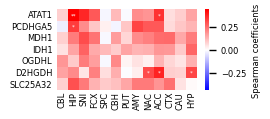

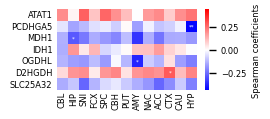

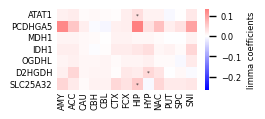

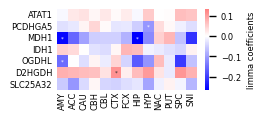

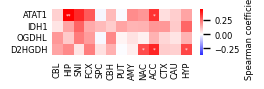

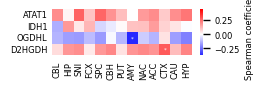

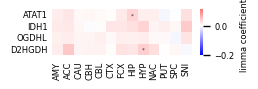

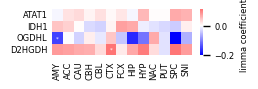

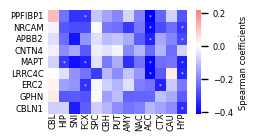

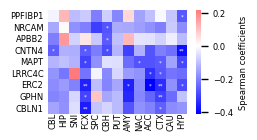

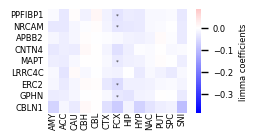

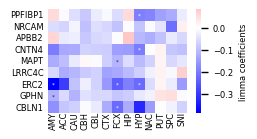

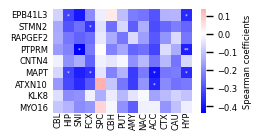

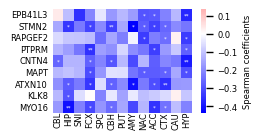

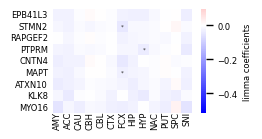

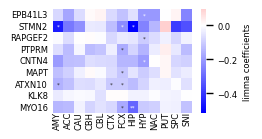

In [ ]:

for i in enrichr.index:
    tterm = enrichr.loc[i, 'Term']
    idxstop = tterm.find(' (GO:')
    dirname = tterm[:idxstop].replace(' ', '_')

    if os.path.isdir(pth + 'figs_lme/GO_Biological_Process/' + dirname) ==False:
        os.mkdir(pth + 'figs_lme/GO_Biological_Process/' + dirname)

    genesnames_list = enrichr.loc[i, 'Genes'].split(';')
    # genesnames_list = enrichr.loc[enrichr.Term == tterm, 'Genes'].str.split(';')
    globalmin = min(spearman_div_coef_df.loc[genesnames_list].min().min(),spearman_tpm_coef_df.loc[genesnames_list].min().min())
    globalmax = max(spearman_div_coef_df.loc[genesnames_list].max().max(),spearman_tpm_coef_df.loc[genesnames_list].max().max()) 

    hm_div = spearman_div_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
    an_div = spearman_div_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)
    an_div = an_div.reindex_like(hm_div)

    fig, ax = plt.subplots(figsize=(2.25,len(genesnames_list)/6.67))
    sns.heatmap(hm_div, 
                annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
                annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients'})
    ax.tick_params(left=False, bottom=False) 
    ax.set_xticklabels(ax.get_xticklabels(),y=0.13)
    ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
    ax.set_ylabel('')
    fig.savefig(pth + 'figs_lme/' + 'GO_Biological_Process/' + dirname + '/' + 'hm_div.spearmanr.png', dpi=300, bbox_inches='tight')
    # plt.close()

    hm_tpm = spearman_tpm_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
    an_tpm = spearman_tpm_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)

    hm_tpm = hm_tpm.reindex_like(hm_div)
    an_tpm = an_tpm.reindex_like(hm_tpm)

    fig, ax = plt.subplots(figsize=(2.25,len(genesnames_list)/6.67))
    sns.heatmap(hm_tpm, 
                annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
                annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients'})
    ax.tick_params(left=False, bottom=False) 
    ax.set_xticklabels(ax.get_xticklabels(),y=0.13)
    ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
    ax.set_ylabel('')

    fig.savefig(pth + 'figs_lme/' + 'GO_Biological_Process/' + dirname + '/' + 'hm_tpm.spearmanr.png', dpi=300, bbox_inches='tight')
    
    
    globalmin = min(limma_coeff_div_df.loc[genesnames_list].min().min(),limma_coeff_tpm_df.loc[genesnames_list].min().min())
    globalmax = max(limma_coeff_div_df.loc[genesnames_list].max().max(),limma_coeff_tpm_df.loc[genesnames_list].max().max()) 
    
    
    hm_div = limma_coeff_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
    an_div = limma_astr_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
    
    fig, ax = plt.subplots(figsize=(2.25,len(genesnames_list)/6.67))
    sns.heatmap(hm_div, 
                annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
                annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients'})
    ax.tick_params(left=False, bottom=False) 
    ax.set_xticklabels(ax.get_xticklabels(),y=0.13)
    ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
    ax.set_ylabel('')
    fig.savefig(pth + 'figs_lme/' + 'GO_Biological_Process/' + dirname + '/' + 'hm_div.limma.png', dpi=300, bbox_inches='tight')
    # plt.close()


    hm_tpm = limma_coeff_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)
    an_tpm = limma_astr_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)

    hm_tpm = hm_tpm.reindex_like(hm_div)
    an_tpm = an_tpm.reindex_like(hm_tpm)

    fig, ax = plt.subplots(figsize=(2.25,len(genesnames_list)/6.67))
    sns.heatmap(hm_tpm, 
                annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
                annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients'})
    ax.tick_params(left=False, bottom=False) 
    ax.set_xticklabels(ax.get_xticklabels(),y=0.13)
    ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
    ax.set_ylabel('')
    fig.savefig(pth + 'figs_lme/' + 'GO_Biological_Process/' + dirname + '/' + 'hm_tpm.limma.png', dpi=300, bbox_inches='tight')
    # plt.close()


### top 30 genes with strongest coefficients in the brain for DIV & insignificant for TPM

In [15]:
significant_div = lme_smtsdbrain_div.loc[(lme_smtsdbrain_div.trend != 'I-DIV0') & (lme_smtsdbrain_div.term == 'age_int')].index
insignificant_tpm = lme_smtsdbrain_tpm.loc[(lme_smtsdbrain_tpm.trend == 'TPM0') & (lme_smtsdbrain_div.term == 'age_int')].index

In [16]:
geneslist = np.intersect1d(significant_div, insignificant_tpm)
len(geneslist)

704

In [ ]:
top30_genes = lme_smtsdbrain_div.loc[(lme_smtsdbrain_div.term == 'age_int') & lme_smtsdbrain_div.index.isin(geneslist)].sort_values('coef', ascending=False).join(gene_info.gene_name).head(30)
bottom30_genes = lme_smtsdbrain_div.loc[(lme_smtsdbrain_div.term == 'age_int') & lme_smtsdbrain_div.index.isin(geneslist)].sort_values('coef', ascending=False).join(gene_info.gene_name).tail(30)
bottom30_genes.sort_values('coef', inplace=True) # turn bottom30_genes to ascending order

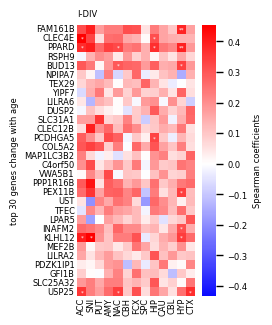

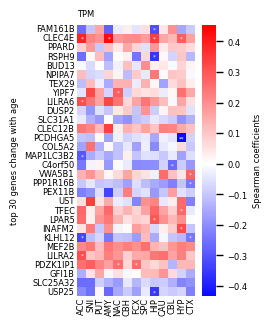

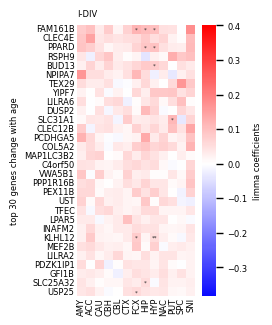

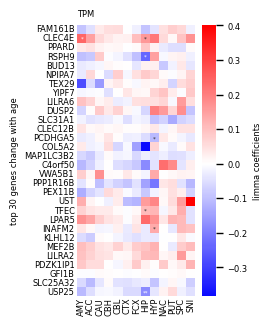

In [ ]:
if os.path.isdir(pth + 'figs_lme/top30/') == False:
    os.mkdir(pth + 'figs_lme/top30/')

h = 8.5
w = 1.9

xx = 0.075
yy = 0.04
genesnames_list = top30_genes.gene_name.to_list()
hm_div = spearman_div_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = spearman_div_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = an_div.reindex_like(hm_div)


globalmin = min(spearman_div_coef_df.loc[genesnames_list].min().min(),spearman_tpm_coef_df.loc[genesnames_list].min().min())
globalmax = max(spearman_div_coef_df.loc[genesnames_list].max().max(),spearman_tpm_coef_df.loc[genesnames_list].max().max()) 

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('top 30 genes change with age')
ax.set_title('I-DIV',loc='left')
fig.savefig(pth + 'figs_lme/top30/' + 'hm_div.spearmanr.png', dpi=300, bbox_inches='tight')
hm_div.to_csv(source_data_path + 'S5f_left.csv.gz', compression='gzip', index=True)


hm_tpm = spearman_tpm_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_tpm = spearman_tpm_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)

hm_tpm = hm_tpm.reindex_like(hm_div)
an_tpm = an_tpm.reindex_like(hm_tpm)

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_tpm, 
            annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('top 30 genes change with age')
ax.set_title('TPM',loc='left')

fig.savefig(pth + 'figs_lme/top30/'+ 'hm_tpm.spearmanr.png', dpi=300, bbox_inches='tight')
hm_div.to_csv(source_data_path + 'S5f_right.csv.gz', compression='gzip', index=True)

hm_div = limma_coeff_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = limma_astr_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = an_div.reindex_like(hm_div)
globalmin = min(limma_coeff_div_df.loc[genesnames_list].min().min(),limma_coeff_tpm_df.loc[genesnames_list].min().min())
globalmax = max(limma_coeff_div_df.loc[genesnames_list].max().max(),limma_coeff_tpm_df.loc[genesnames_list].max().max()) 



fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('top 30 genes change with age')
ax.set_title('I-DIV',loc='left')
fig.savefig(pth + 'figs_lme/top30/' + 'hm_div.limma.png', dpi=300, bbox_inches='tight')
hm_div.to_csv(source_data_path + '4g_left.csv.gz', compression='gzip', index=True)


hm_tpm = limma_coeff_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_tpm = limma_astr_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)

hm_tpm = hm_tpm.reindex_like(hm_div)
an_tpm = an_tpm.reindex_like(hm_tpm)

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_tpm, 
            annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('top 30 genes change with age')
ax.set_title('TPM',loc='left')
fig.savefig(pth + 'figs_lme/top30/'+ 'hm_tpm.limma.png', dpi=300, bbox_inches='tight')
hm_div.to_csv(source_data_path + '4g_right.csv.gz', compression='gzip', index=True)

** counts **
n 20-49: 14
n 50-59: 37
n 60-79: 56
AGE coefficient = 0.10, fdr = 0.02 
        


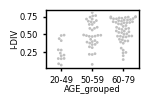

In [ ]:
gn = 'PPARD' ; subt='Brain - Hypothalamus'

if os.path.isdir(pth + 'figs_lme/' + gn) ==False:
    os.mkdir(pth + 'figs_lme/' + gn)
plotdf = make_swarmplot_df(subt=subt, gene=gn)
plotdf.to_csv(source_data_path + '4h.csv.gz')
isoforms_df = get_isoforms_from_gene(gene = gn)
isoforms_df.to_csv(source_data_path + '4ij.csv.gz')

fig, ax = plt.subplots(figsize=(1.2, 0.75))
sns.swarmplot(data=plotdf, x='AGE_grouped', y=gn, order=['20-49', '50-59', '60-79'], c = 'silver', s=2, edgecolor='None')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)
ax.set_ylabel('I-DIV')

s = f'''** counts **
n 20-49: {len(plotdf.loc[plotdf.AGE_grouped == '20-49', gn])}
n 50-59: {len(plotdf.loc[plotdf.AGE_grouped == '50-59', gn])}
n 60-79: {len(plotdf.loc[plotdf.AGE_grouped == '60-79', gn])}
AGE coefficient = {limma_coeff_div_df.loc[gn, subt]:.2f}, fdr = {limma_fdr_div_df.loc[gn, subt]:.2f} 
        ''' 
fig.savefig(pth + '/figs_lme/' + gn + '/Hypothalamus.barplot.swarmplot.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + 'figs_lme/' + gn + '/Hypothalamus.' + 'about.txt', 'w') as f:
    f.write(s)
    f.close()
print(s)
isoform_expression_barplots(gene=gn,isoforms_df=isoforms_df, subt=subt, savefig=True, path_and_name =pth + 'figs_lme/' + gn + '/Hypothalamus.barplot')
isoform_meanexpression_lineplot(isoforms_df,subt, savefig=True, path_and_name =pth + 'figs_lme/' + gn + '/Hypothalamus.lineplot')

In [29]:
limma_coeff_div_df.loc[gn, subt]

0.0952819448208665

In [30]:
limma_fdr_div_df.loc[gn, subt]

0.0153400097313284

** counts **
n 20-49: 23
n 50-59: 50
n 60-79: 66
AGE coefficient = 0.10, fdr = 0.04 
        


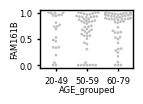

In [ ]:
# gn = 'FAM161B'

# if os.path.isdir('figs_lme/' + gn) ==False:
#     os.mkdir('figs_lme/' + gn)
# plotdf = make_swarmplot_df(subt='Brain - Nucleus accumbens (basal ganglia)', gene=gn)
# isoforms_df = get_isoforms_from_gene(gene = gn)

# fig, ax = plt.subplots(figsize=(1.2, 0.75))
# sns.swarmplot(data=plotdf, x='AGE_grouped', y=gn, order=['20-49', '50-59', '60-79'], c = 'silver', s=2, edgecolor='None')
# ax.tick_params(length=2.5)
# ax.set_yticklabels(ax.get_yticklabels(), x=0)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
# ax.set_xlabel(ax.get_xlabel(), labelpad=0)
# ax.set_ylabel(ax.get_ylabel(), labelpad=0)

# s = f'''** counts **
# n 20-49: {len(plotdf.loc[plotdf.AGE_grouped == '20-49', gn])}
# n 50-59: {len(plotdf.loc[plotdf.AGE_grouped == '50-59', gn])}
# n 60-79: {len(plotdf.loc[plotdf.AGE_grouped == '60-79', gn])}
# AGE coefficient = {limma_coeff_div_df.loc[gn, subt]:.2f}, fdr = {limma_fdr_div_df.loc[gn, subt]:.2f} 
#         ''' 
# fig.savefig('figs_lme/' + gn + '/Nucleus_accumbens.swarmplot.png', format='png', dpi=300, bbox_inches='tight')
# print(s)
# isoform_expression_barplots(gene=gn,isoforms_df=isoforms_df, subt='Brain - Nucleus accumbens (basal ganglia)', savefig=True, path_and_name = 'figs_lme/' + gn + '/Nucleus_accumbens.barplot')
# isoforms_df.to_csv(source_data_path + 'S5h_right.csv.gz')

** counts **
n 20-49: 15
n 50-59: 42
n 60-79: 54
AGE coefficient = 0.10, fdr = 0.04 
        


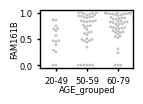

In [ ]:
gn = 'FAM161B'

if os.path.isdir(pth + 'figs_lme/' + gn) ==False:
    os.mkdir(pth + 'figs_lme/' + gn)
plotdf = make_swarmplot_df(subt='Brain - Frontal Cortex (BA9)', gene=gn)
isoforms_df = get_isoforms_from_gene(gene = gn)

fig, ax = plt.subplots(figsize=(1.2, 0.75))
sns.swarmplot(data=plotdf, x='AGE_grouped', y=gn, order=['20-49', '50-59', '60-79'], c = 'silver', s=2, edgecolor='None')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)

s = f'''** counts **
n 20-49: {len(plotdf.loc[plotdf.AGE_grouped == '20-49', gn])}
n 50-59: {len(plotdf.loc[plotdf.AGE_grouped == '50-59', gn])}
n 60-79: {len(plotdf.loc[plotdf.AGE_grouped == '60-79', gn])}
AGE coefficient = {limma_coeff_div_df.loc[gn, subt]:.2f}, fdr = {limma_fdr_div_df.loc[gn, subt]:.2f} 
        ''' 
fig.savefig(pth + f'figs_lme/{gn}/Frontal_Cortex.swarmplot.png', format='png', dpi=300, bbox_inches='tight')
print(s)
with open('figs_lme/' + gn + '/Frontal_Cortex.' + 'about.txt', 'w') as f:
    f.write(s)
    f.close()


isoform_expression_barplots(gene=gn,isoforms_df=isoforms_df, subt='Brain - Frontal Cortex (BA9)', savefig=True, path_and_name = pth + 'figs_lme/' + gn + '/Frontal_Cortex.barplot')
isoforms_df.to_csv(source_data_path + 'S5h_left.csv.gz')

** counts **
n 20-49: 16
n 50-59: 33
n 60-79: 49
AGE coefficient = 0.10, fdr = 0.04 
        


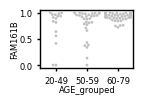

In [ ]:
gn = 'FAM161B'

if os.path.isdir('figs_lme/' + gn) ==False:
    os.mkdir('figs_lme/' + gn)
plotdf = make_swarmplot_df(subt='Brain - Hippocampus', gene=gn)
isoforms_df = get_isoforms_from_gene(gene = gn)

fig, ax = plt.subplots(figsize=(1.2, 0.75))
sns.swarmplot(data=plotdf, x='AGE_grouped', y=gn, order=['20-49', '50-59', '60-79'], c = 'silver', s=2, edgecolor='None')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)

s = f'''** counts **
n 20-49: {len(plotdf.loc[plotdf.AGE_grouped == '20-49', gn])}
n 50-59: {len(plotdf.loc[plotdf.AGE_grouped == '50-59', gn])}
n 60-79: {len(plotdf.loc[plotdf.AGE_grouped == '60-79', gn])}
AGE coefficient = {limma_coeff_div_df.loc[gn, subt]:.2f}, fdr = {limma_fdr_div_df.loc[gn, subt]:.2f} 
        ''' 
fig.savefig('figs_lme/' + gn + '/Hippocampus.swarmplot.png', format='png', dpi=300, bbox_inches='tight')
with open('figs_lme/' + gn + '/Hippocampus.' + 'about.txt', 'w') as f:
    f.write(s)
    f.close()
print(s)
isoform_expression_barplots(gene=gn,isoforms_df=isoforms_df, subt='Brain - Hippocampus', savefig=True, path_and_name = 'figs_lme/' + gn + '/Hippocampus.barplot')
isoforms_df.to_csv(source_data_path + 'S5h_center.csv.gz')

** counts **
n 20-49: 14
n 50-59: 37
n 60-79: 56
        


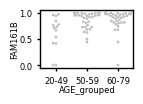

In [ ]:
gn = 'FAM161B'

if os.path.isdir(pth + 'figs_lme/' + gn) ==False:
    os.mkdir(pth + 'figs_lme/' + gn)
plotdf = make_swarmplot_df(subt='Brain - Hypothalamus', gene=gn)
isoforms_df = get_isoforms_from_gene(gene = gn)

fig, ax = plt.subplots(figsize=(1.2, 0.75))
sns.swarmplot(data=plotdf, x='AGE_grouped', y=gn, order=['20-49', '50-59', '60-79'], c = 'silver', s=2, edgecolor='None')
ax.tick_params(length=2.5)
ax.set_yticklabels(ax.get_yticklabels(), x=0)
ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
ax.set_xlabel(ax.get_xlabel(), labelpad=0)
ax.set_ylabel(ax.get_ylabel(), labelpad=0)

s = f'''** counts **
n 20-49: {len(plotdf.loc[plotdf.AGE_grouped == '20-49', gn])}
n 50-59: {len(plotdf.loc[plotdf.AGE_grouped == '50-59', gn])}
n 60-79: {len(plotdf.loc[plotdf.AGE_grouped == '60-79', gn])}
        ''' 
fig.savefig(pth + 'figs_lme/' + gn + '/Hypothalamus.barplot.swarmplot.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + 'figs_lme/' + gn + '/Hypothalamus.' + 'about.txt', 'w') as f:
    f.write(s)
    f.close()
print(s)
isoform_expression_barplots(gene=gn,isoforms_df=isoforms_df, subt='Brain - Hypothalamus', savefig=True, path_and_name = pth + 'figs_lme/' + gn +'/Hypothalamus.barplot')
isoforms_df.to_csv(source_data_path + 'S5h_right.csv.gz')

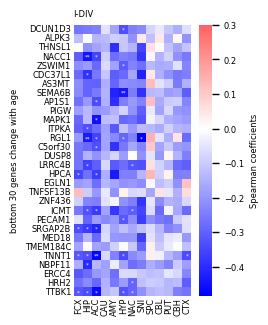

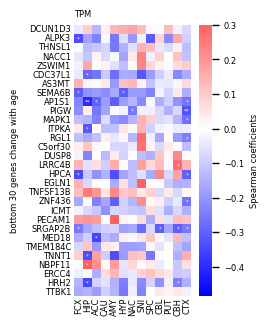

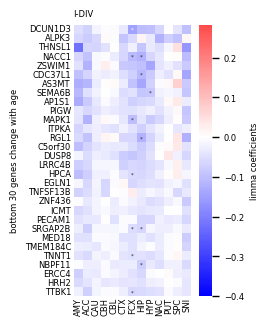

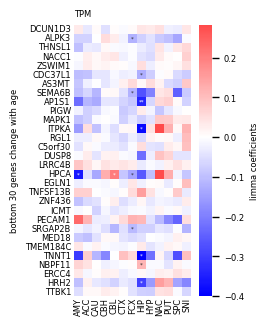

In [ ]:
if os.path.isdir('figs_lme/bottom30') == False:
    os.mkdir('figs_lme/bottom30')


h = 8.5
w = 1.9

xx = 0.075
yy = 0.04

genesnames_list = bottom30_genes.gene_name.to_list()
hm_div = spearman_div_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = spearman_div_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = an_div.reindex_like(hm_div)


globalmin = min(spearman_div_coef_df.loc[genesnames_list].min().min(),spearman_tpm_coef_df.loc[genesnames_list].min().min())
globalmax = max(spearman_div_coef_df.loc[genesnames_list].max().max(),spearman_tpm_coef_df.loc[genesnames_list].max().max()) 

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('bottom 30 genes change with age')
ax.set_title('I-DIV',loc='left')
fig.savefig('figs_lme/' +'bottom30/' + 'hm_div.spearmanr.png', dpi=300, bbox_inches='tight')
# plt.close()


hm_tpm = spearman_tpm_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_tpm = spearman_tpm_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)

hm_tpm = hm_tpm.reindex_like(hm_div)
an_tpm = an_tpm.reindex_like(hm_tpm)

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_tpm, 
            annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('bottom 30 genes change with age')
ax.set_title('TPM',loc='left')

fig.savefig('figs_lme/' +'bottom30/'+ 'hm_tpm.spearmanr.png', dpi=300, bbox_inches='tight')


hm_div = limma_coeff_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = limma_astr_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = an_div.reindex_like(hm_div)
globalmin = min(limma_coeff_div_df.loc[genesnames_list].min().min(),limma_coeff_tpm_df.loc[genesnames_list].min().min())
globalmax = max(limma_coeff_div_df.loc[genesnames_list].max().max(),limma_coeff_tpm_df.loc[genesnames_list].max().max()) 


fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('bottom 30 genes change with age')
ax.set_title('I-DIV',loc='left')
fig.savefig('figs_lme/' +'bottom30/' + 'hm_div.limma.png', dpi=300, bbox_inches='tight')
hm_div.to_csv(source_data_path + 'S5g_left.csv.gz', compression='gzip', index=True)


hm_tpm = limma_coeff_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_tpm = limma_astr_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)

hm_tpm = hm_tpm.reindex_like(hm_div)
an_tpm = an_tpm.reindex_like(hm_tpm)

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_tpm, 
            annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients'})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=yy)
ax.set_yticklabels(ax.get_yticklabels(),x=xx)
ax.set_ylabel('bottom 30 genes change with age')
ax.set_title('TPM',loc='left')
fig.savefig('figs_lme/' +'bottom30/'+ 'hm_tpm.limma.png', dpi=300, bbox_inches='tight')
hm_tpm.to_csv(source_data_path + 'S5g_right.csv.gz', compression='gzip', index=True)

#### PPARD family

In [ ]:
if not os.path.isdir('figs_lme/PPARD_family/'):
    os.mkdir('figs_lme/PPARD_family/')

Text(0.0, 1.0, 'I-DIV')

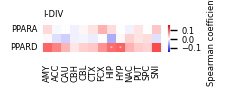

In [73]:
fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients', 'shrink':1})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=0)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
ax.set_ylabel('')
ax.set_title('I-DIV',loc='left')

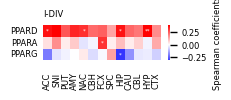

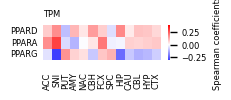

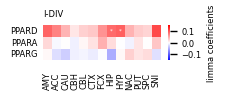

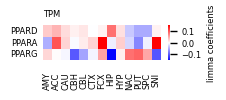

In [ ]:
if os.path.isdir('PPARD_family') == False:
    os.mkdir('PPARD_family')
genesnames_list = ['PPARD','PPARA', 'PPARG']
hm_div = spearman_div_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = spearman_div_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = an_div.reindex_like(hm_div)

h = 6.5
w = 1.9
globalmin = min(spearman_div_coef_df.loc[genesnames_list].min().min(),spearman_tpm_coef_df.loc[genesnames_list].min().min())
globalmax = max(spearman_div_coef_df.loc[genesnames_list].max().max(),spearman_tpm_coef_df.loc[genesnames_list].max().max()) 

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients', 'shrink':1})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=0)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
ax.set_ylabel('')
ax.set_title('I-DIV',loc='left')
fig.savefig('figs_lme/' +'PPARD_family/'+ 'hm_div.spearmanr.png', dpi=300, bbox_inches='tight')


hm_tpm = spearman_tpm_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_tpm = spearman_tpm_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)

hm_tpm = hm_tpm.reindex_like(hm_div)
an_tpm = an_tpm.reindex_like(hm_tpm)

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_tpm, 
            annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients', 'shrink':1})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=0)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
ax.set_ylabel('')
ax.set_title('TPM',loc='left')

fig.savefig('figs_lme/' +'PPARD_family/'+ 'hm_tpm.spearmanr.png', dpi=300, bbox_inches='tight')


hm_div = limma_coeff_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = limma_astr_div_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_div = an_div.reindex_like(hm_div)
globalmin = min(limma_coeff_div_df.loc[genesnames_list].min().min(),limma_coeff_tpm_df.loc[genesnames_list].min().min())
globalmax = max(limma_coeff_div_df.loc[genesnames_list].max().max(),limma_coeff_tpm_df.loc[genesnames_list].max().max()) 


fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients', 'shrink':1})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=0)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
ax.set_ylabel('')
ax.set_title('I-DIV',loc='left')
fig.savefig('figs_lme/' +'PPARD_family/' + 'hm_div.limma.png', dpi=300, bbox_inches='tight')
hm_div.to_csv(source_data_path + 'S5i_left.csv.gz', compression='gzip', index=True)


hm_tpm = limma_coeff_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)
an_tpm = limma_astr_tpm_df.loc[genesnames_list].rename(columns = brain_regions_abb)

hm_tpm = hm_tpm.reindex_like(hm_div)
an_tpm = an_tpm.reindex_like(hm_tpm)

fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_tpm, 
            annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients', 'shrink':1})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=0)
ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
ax.set_ylabel('')
ax.set_title('TPM',loc='left')
fig.savefig('figs_lme/' +'PPARD_family/'+ 'hm_tpm.limma.png', dpi=300, bbox_inches='tight')
an_tpm.to_csv(source_data_path + 'S5i_right.csv.gz', compression='gzip', index=True)

### limma smts

In [ ]:
tissues_dirs = [f.split('.')[0] for f in os.listdir(multiple_linear_regression_path + 'SMTS/') if f.endswith('.limma.tpm.coefficients.csv.gz')]

smts_limma_tpm = pd.concat([pd.read_csv(multiple_linear_regression_path + f'{t}.limma.tpm.coefficients.csv.gz').assign(SMTSD=t) for t in tissues_dirs])
smts_limma_div = pd.concat([pd.read_csv(multiple_linear_regression_path + f'{t}.limma.div.coefficients.csv.gz').assign(SMTSD=t) for t in tissues_dirs])


In [8]:
genesnames_list = ['PPARD','PPARA', 'PPARG']
smts_ppardfamily_div_coef = smts_limma_div.loc[smts_limma_div.gene.isin(gene_info.loc[gene_info.gene_name.isin(genesnames_list)].index), ['age_int_coef', 'age_int_FDR','tissue', 'gene']].pivot(index='gene', columns='tissue', values='age_int_coef')
smts_ppardfamily_div_fdr = smts_limma_div.loc[smts_limma_div.gene.isin(gene_info.loc[gene_info.gene_name.isin(genesnames_list)].index), ['age_int_coef', 'age_int_FDR','tissue', 'gene']].pivot(index='gene', columns='tissue', values='age_int_FDR')

smts_ppardfamily_div_coef = smts_ppardfamily_div_coef.join(gene_info.gene_name).set_index('gene_name')
smts_ppardfamily_div_fdr = smts_ppardfamily_div_fdr.join(gene_info.gene_name).set_index('gene_name')
smts_ppardfamily_div_ast = smts_ppardfamily_div_fdr.applymap(pval_to_asterisks)

smts_ppardfamily_tpm_coef = smts_limma_tpm.loc[smts_limma_tpm.gene.isin(gene_info.loc[gene_info.gene_name.isin(genesnames_list)].index), ['age_int_coef', 'age_int_FDR','tissue', 'gene']].pivot(index='gene', columns='tissue', values='age_int_coef')
smts_ppardfamily_tpm_fdr = smts_limma_tpm.loc[smts_limma_tpm.gene.isin(gene_info.loc[gene_info.gene_name.isin(genesnames_list)].index), ['age_int_coef', 'age_int_FDR','tissue', 'gene']].pivot(index='gene', columns='tissue', values='age_int_FDR')

smts_ppardfamily_tpm_coef = smts_ppardfamily_tpm_coef.join(gene_info.gene_name).set_index('gene_name')
smts_ppardfamily_tpm_fdr = smts_ppardfamily_tpm_fdr.join(gene_info.gene_name).set_index('gene_name')
smts_ppardfamily_tpm_ast = smts_ppardfamily_tpm_fdr.applymap(pval_to_asterisks)

Text(0.0, 1.0, 'TPM')

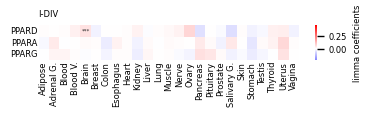

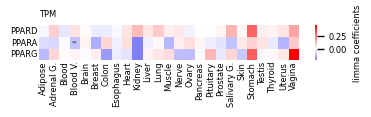

In [9]:
if os.path.isdir('PPARD_family') == False:
    os.mkdir('PPARD_family')
genesnames_list = ['PPARD','PPARA', 'PPARG']
# hm_div = spearman_div_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
# an_div = spearman_div_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)
# an_div = an_div.reindex_like(hm_div)

h = 6.5
w = 4.2
# glo4.balmin = min(spearman_div_coef_df.loc[genesnames_list].min().min(),spearman_tpm_coef_df.loc[genesnames_list].min().min())
# globalmax = max(spearman_div_coef_df.loc[genesnames_list].max().max(),spearman_tpm_coef_df.loc[genesnames_list].max().max()) 

# fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
# sns.heatmap(hm_div, 
#             annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
#             annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients', 'shrink':1})
# ax.tick_params(left=False, bottom=False) 
# ax.set_xticklabels(ax.get_xticklabels(),y=0)
# ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
# ax.set_ylabel('')
# ax.set_title('I-DIV',loc='left')
# fig.savefig('PPARD_family/'+ 'smts.hm_div.spearmanr.png', dpi=300, bbox_inches='tight')


# hm_tpm = spearman_tpm_coef_df.loc[genesnames_list].rename(columns = brain_regions_abb)
# an_tpm = spearman_tpm_astr_df.loc[genesnames_list].rename(columns = brain_regions_abb)

# hm_tpm = hm_tpm.reindex_like(hm_div)
# an_tpm = an_tpm.reindex_like(hm_tpm)

# fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
# sns.heatmap(hm_tpm, 
#             annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
#             annot_kws={'fontsize': 4}, cbar_kws={'label': 'Spearman coefficients', 'shrink':1})
# ax.tick_params(left=False, bottom=False) 
# ax.set_xticklabels(ax.get_xticklabels(),y=0)
# ax.set_yticklabels(ax.get_yticklabels(),x=0.05)
# ax.set_ylabel('')
# ax.set_title('TPM',loc='left')

# fig.savefig('PPARD_family/'+ 'smts.hm_tpm.spearmanr.png', dpi=300, bbox_inches='tight')


hm_div = smts_ppardfamily_div_coef.loc[genesnames_list].rename(columns = abb_SMTS)
an_div = smts_ppardfamily_div_ast.loc[genesnames_list].rename(columns = abb_SMTS)
an_div = an_div.reindex_like(hm_div)
globalmin = min(smts_ppardfamily_div_coef.loc[genesnames_list].min().min(),smts_ppardfamily_tpm_coef.loc[genesnames_list].min().min())
globalmax = max(smts_ppardfamily_div_coef.loc[genesnames_list].max().max(),smts_ppardfamily_tpm_coef.loc[genesnames_list].max().max()) 


fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_div, 
            annot = an_div,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients', 'shrink':1})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=0.3)
ax.set_yticklabels(ax.get_yticklabels(),x=0.04)
ax.set_ylabel('')
ax.set_title('I-DIV',loc='left')
# fig.savefig('PPARD_family/' + 'smts.hm_div.limma.png', dpi=300, bbox_inches='tight')
# plt.close()


hm_tpm = smts_ppardfamily_tpm_coef.loc[genesnames_list].rename(columns = abb_SMTS)
an_tpm = smts_ppardfamily_tpm_ast.loc[genesnames_list].rename(columns = abb_SMTS)

hm_tpm = hm_tpm.reindex_like(hm_div)
an_tpm = an_tpm.reindex_like(hm_tpm)



fig, ax = plt.subplots(figsize=(w,len(genesnames_list)/h))
sns.heatmap(hm_tpm, 
            annot = an_tpm,vmin=globalmin,vmax = globalmax, cmap='bwr', fmt='', center=0,
            annot_kws={'fontsize': 4}, cbar_kws={'label': 'limma coefficients', 'shrink':1})
ax.tick_params(left=False, bottom=False) 
ax.set_xticklabels(ax.get_xticklabels(),y=0.3)
ax.set_yticklabels(ax.get_yticklabels(),x=0.04)
ax.set_ylabel('')
ax.set_title('TPM',loc='left')
# fig.savefig('PPARD_family/'+ 'smts.hm_tpm.limma.png', dpi=300, bbox_inches='tight')
# plt.close()

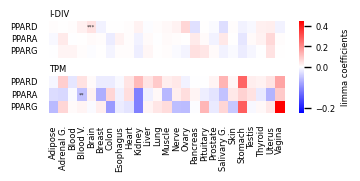

In [ ]:
import matplotlib.colors as clt

# give a little more room for titles in the two-panel heatmap
fig.subplots_adjust(top=0.88, bottom=0.18, left=0.14, right=0.92)

fig, (ax_div, ax_tpm) = plt.subplots(
    2, 1,
    figsize=(w, 1.2),
    sharex=True,
    gridspec_kw={'hspace': 0.5}
)

for ax, data, annot, title in [
    (ax_div, hm_div, an_div, 'I-DIV'),
    (ax_tpm, hm_tpm, an_tpm, 'TPM'),
]:
    sns.heatmap(
        data,
        annot=annot,
        vmin=globalmin,vmax = globalmax, center=0,
        cmap='bwr',
        fmt='',
        annot_kws={'fontsize': 4},
        cbar=False,
        ax=ax
    )
    ax.tick_params(left=False, bottom=False)
    ax.set_ylabel('')
    ax.set_title(title, loc='left', pad=3)

ax_div.tick_params(axis='x', labelbottom=False)
ax_tpm.set_xticklabels(ax_tpm.get_xticklabels(), rotation=90, ha='center')
ax_tpm.tick_params(axis='x', pad=4)
norm = clt.Normalize(vmin=globalmin, vmax=globalmax)
sm = plt.cm.ScalarMappable(norm=norm, cmap='bwr')
# sm = plt.get_cmap('bwr')
sm.set_array([])
cbar = fig.colorbar(sm, ax=[ax_div, ax_tpm], location='right', label='limma coefficients')

# Add an extra tick at -1 to the existing colorbar

# ticks = np.unique(np.concatenate([np.asarray(cbar.get_ticks(), dtype=float), [-1.0]]))
# cbar.set_ticks(ticks)

cbar.outline.set_visible(False)

fig.savefig('figs_lme/' + 'PPARD_family/'+ 'smts.limma.png', dpi=300, bbox_inches='tight')
hm_div.to_csv(source_data_path + 'S5j_top.csv.gz', compression='gzip', index=True)
hm_tpm.to_csv(source_data_path + 'S5j_bottom.csv.gz', compression='gzip', index=True)

# count significant genes on the SMTS level: limma & Spearman 

In [136]:
smts_limcount_df = pd.DataFrame(index = metadata.SMTS.unique())
smts_limcount_df = smts_limcount_df.assign(age_tpm = smts_limma_tpm.loc[smts_limma_tpm.age_int_FDR < 0.05].groupby('tissue').size(), 
                                     age_div = smts_limma_div.loc[smts_limma_div.age_int_FDR < 0.05].groupby('tissue').size(), 
                                     sex_div = smts_limma_div.loc[smts_limma_div.SEXFemale_FDR < 0.05].groupby('tissue').size(),
                                     sex_tpm = smts_limma_tpm.loc[smts_limma_tpm.SEXFemale_FDR < 0.05].groupby('tissue').size(),
                                     rin_tpm = smts_limma_tpm.loc[smts_limma_div.SMRIN_FDR < 0.05].groupby('tissue').size(), 
                                     rin_div = smts_limma_div.loc[smts_limma_div.SMRIN_FDR < 0.05].groupby('tissue').size(), 
                                     isc_tpm = smts_limma_tpm.loc[smts_limma_tpm.SMTSISCH_FDR < 0.05].groupby('tissue').size(),
                                     isc_div = smts_limma_div.loc[smts_limma_div.SMTSISCH_FDR < 0.05].groupby('tissue').size(),
                                     n=metadata.SMTS.value_counts())

smts_limcount_df.fillna(0, inplace=True)
smts_limcount_df = smts_limcount_df.astype(int)
smts_limcount_df.sort_values('n', ascending=False, inplace=True)
smts_limcount_df

,age_tpm,age_div,sex_div,sex_tpm,rin_tpm,rin_div,isc_tpm,isc_div,n
Brain,8173,3945,1056,5278,9681,9681,3566,776,1454
Skin,199,13,7,1388,3209,3209,55,2,527
Blood Vessel,3777,293,3,102,2581,2581,1,0,305
Adipose Tissue,258,0,0,257,1091,1091,348,58,302
Blood,41,0,0,4,4550,4550,647,279,245
Esophagus,10,11,0,5,6044,6044,1564,295,232
Muscle,581,5,2,169,1218,1218,0,0,232
Heart,10,0,1,6,4894,4894,1,2,225
Thyroid,36,0,9,1412,823,823,316,397,172
Pituitary,14,0,6,507,2406,2406,7,0,170


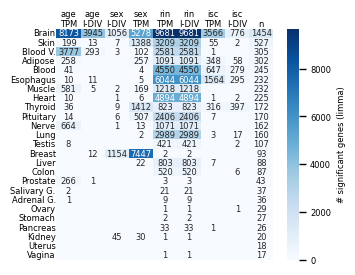

In [ ]:
lim_annotations = smts_limcount_df.astype(str).replace('0', '')

fig, ax = plt.subplots(figsize=(3.5, 3))
sns.heatmap(smts_limcount_df, annot=lim_annotations, fmt='', cmap='Blues', ax=ax, cbar_kws={'label': '# significant genes (limma)'})
ax.xaxis.tick_top()
ax.set_xticklabels([x.get_text().replace('_', '\n').replace('div', 'I-DIV').replace('tpm', 'TPM') for x in ax.get_xticklabels()], rotation=0, ha='center', y = 0.95)
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()], x = 0.05)
ax.tick_params(left=False, bottom=False, top=False) 
fig.savefig('figs_lme/overview_age/' + 'limma.smts.count.png', dpi=300, bbox_inches='tight')

In [ ]:
tissues_dirs = [f.split('.')[0] for f in os.listdir('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/spearman/SMTS/') if f.endswith('.spearmanr.tpm.csv.gz')]

smts_spearmanr_tpm = pd.concat([pd.read_csv(spearman_path + f'SMTS/{t}.spearmanr.tpm.csv.gz').assign(SMTS=t) for t in tissues_dirs])
smts_spearmanr_div = pd.concat([pd.read_csv(spearman_path + f'SMTS/{t}.spearmanr.div.csv.gz').assign(SMTS=t) for t in tissues_dirs])

# Correct p-values for every gene within each tissue (SMTS)
smts_spearmanr_tpm['fdr'] = (smts_spearmanr_tpm.groupby('SMTS')['p_val'].transform(lambda p: correct_pvalues_with_nan(p, method='fdr_bh', alpha=0.05)[1]))
smts_spearmanr_div['fdr'] = (smts_spearmanr_div.groupby('SMTS')['p_val'].transform(lambda p: correct_pvalues_with_nan(p, method='fdr_bh', alpha=0.05)[1]))

In [148]:
smts_sprcount_df = pd.DataFrame(index = metadata.SMTS.unique())
smts_sprcount_df = smts_sprcount_df.assign(age_tpm = smts_spearmanr_tpm.loc[smts_spearmanr_tpm.fdr < 0.05].groupby('SMTS').size(), 
                                           age_div = smts_spearmanr_div.loc[smts_spearmanr_div.fdr < 0.05].groupby('SMTS').size(), 
                                           n = metadata.SMTS.value_counts())
smts_sprcount_df.fillna(0, inplace=True)
smts_sprcount_df = smts_sprcount_df.astype(int)
smts_sprcount_df.sort_values('n', ascending=False, inplace=True)
smts_sprcount_df

,age_tpm,age_div,n
Brain,7142,5483,1454
Skin,10,1,527
Blood Vessel,3658,206,305
Adipose Tissue,81,1,302
Blood,2,0,245
Esophagus,0,3,232
Muscle,993,3,232
Heart,2,0,225
Thyroid,117,17,172
Pituitary,23,0,170


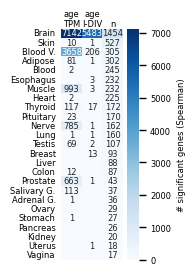

In [ ]:
spr_annotations = smts_sprcount_df.astype(str).replace('0', '')

fig, ax = plt.subplots(figsize=(1, 3))
sns.heatmap(smts_sprcount_df, annot=spr_annotations, fmt='', cmap='Blues', ax=ax, cbar_kws={'label': '# significant genes (Spearman)'})
ax.xaxis.tick_top()
ax.set_xticklabels([x.get_text().replace('_', '\n').replace('div', 'I-DIV').replace('tpm', 'TPM') for x in ax.get_xticklabels()], rotation=0, ha='center', y = 0.95)
ax.tick_params(left=False, bottom=False, top=False) 
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()], x = 0.1)
fig.savefig('figs_lme/overview_age/' + 'spearmanr.smts.count.png', dpi=300, bbox_inches='tight')